# 02 — Feature engineering (the pipeline is built here)

This notebook turns the panel into a scikit-learn Pipeline (`src/features.py`). Every step that learns something from data sits inside the Pipeline, so it is refit inside each CV fold. I then check each feature-engineering step (impute, encode, transform, create, select) against the real panel and decide the feature set notebook 04 uses.

**Inputs:** `panel.parquet` (development block only), `results.json:nb01/chosen_lags`.
**Outputs:** ledger block `nb02` (CV MAE, leakage arms, encoding scores, `nb02/encoding_chosen`, MI and VIF tables); figures `02_pipeline_map`, `02_encoding_comparison`, `02_imputation`, `02_encodings`, `02_log_transform`, `02_scaling`, `02_cyclical`, `02_mi_vs_pearson`, `02_leakage_fuel_columns`, `02_per_zone_relative`, `02_mi_stability`, `02_vif`, `02_forward_selection`, `02_shap_selection`.


### 2.1 — Setup

Load the development block and the lag set chosen in notebook 01. The lags are read from the ledger, not retyped.


In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R

pd.set_option("display.width", 140, "display.max_columns", 50)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

# The development block only (up to cfg.HOLDOUT_CUT). Every cross-validation and
# diagnostic in this notebook informs a modelling decision, so none may see the holdout
# notebook 04 scores; the distribution figure of section 2.12 reads the panel itself.
df = pd.read_parquet(cfg.PANEL)
df = df[df[cfg.TIME_COL] <= cfg.HOLDOUT_CUT].reset_index(drop=True)
lags = tuple(R.require('nb01', 'chosen_lags'))
y = df[cfg.TARGET].copy()
print(df.shape, lags)

(268186, 35) (1, 2, 3, 24, 168)


### 2.2 — The transformers

Print the source of `GroupLagFeatures` from `src/features.py`. Its `fit` stores the last 168 training rows of each zone (the history buffer), and `transform` prepends them, so lags on the first validation rows come from the training window only.


In [2]:
import inspect
from src import features as P
print(inspect.getsource(P.GroupLagFeatures))

class GroupLagFeatures(BaseEstimator, TransformerMixin):
    """Per-zone lags and rolling statistics of the target, with a history buffer.

    `fit` remembers the last `buffer_` rows of each zone in the TRAINING window.
    `transform` prepends that buffer to the rows it is given, computes the
    features on the concatenation, then returns only the requested rows. Result:
    the first row of a validation fold has a real 168-hour lag instead of NaN,
    and that lag is built from training-window observations only.

    WHY LAGGING THE TARGET IS NOT LEAKAGE: every lag is >= 1 hour, so no row ever
    sees its own value. At operational prediction time the operator does know
    yesterday's realised net load. `min(lags) >= 1` is asserted in `fit` rather
    than trusted.

    WHY ROLLING WINDOWS END AT THE FORECAST ORIGIN: `rolling(24).mean()` includes
    the current row, so the window has to exclude it. But excluding only the
    current row is right at h=1 and wrong at every longer h

### 2.3 — Assemble the pipeline

Build the Pipeline and fit it once as a smoke test. The step names should print in order. The encoder is pinned to `target` here because 2.5 tests target-encoding leakage.


In [3]:
# encoding pinned EXPLICITLY: 2.5 is a target-encoder leakage demonstration, so
# its clean arm must be a target encoder. The pipeline DEFAULT is now 'onehot'
# (the 2.7 decision) -- pinning here keeps 2.4-2.5 measuring what they claim to.
pipe = P.make_supervised_pipeline(numeric_cols=cfg.NUMERIC_FEATURES, lags=lags,
                                  encoding='target')
print([name for name, _ in pipe.steps])
pipe.fit(df, y)
print('selected features:', pipe.named_steps['select'].selected_[:10], '...')

['calendar', 'lag', 'relative', 'weather', 'swap', 'derive', 'encode', 'ablate', 'select', 'impute', 'model']


selected features: ['temp', 'humidity', 'wind_speed', 'cloud_cover', 'ghi', 'dni_horiz', 'dhi', 'wind_speed_100m', 'wind_gust', 'apparent_temp'] ...


### 2.4 — Cross-validate with TimeSeriesSplit and a gap

`PanelTimeSeriesSplit` uses expanding windows split on timestamps, not rows, so no hour straddles a train/validation boundary. The 168 h gap (the longest rolling window) drops the week after each training window. The cost is that lags in the first validation week fall into the gap and are partly missing (§2.6).

Fold 1 has the least training data but scores best, and the last fold worst (510.0 vs 589.6 MW): later windows are harder, so read the per-fold row, not only the mean.


In [4]:
from sklearn.model_selection import cross_val_score
cv = P.make_ts_cv(n_splits=cfg.N_SPLITS, gap=cfg.CV_GAP)
sc = -cross_val_score(pipe, df, y, cv=cv, scoring='neg_mean_absolute_error')
print('MAE per fold:', np.round(sc, 1), '| mean', round(sc.mean(), 1))

MAE per fold: [510.  512.2 541.2 552.2 589.6] | mean 541.1


### 2.5 — Leakage evidence

Score three arms: no zone encoding, a target encoder refit inside each fold, and a target encoding computed once on the whole development block (leaked).


In [5]:
# The leakage experiment needs THREE arms, not two. With only "correct" and
# "leaked", a gap of zero is ambiguous: it could mean the leak is harmless, or
# that the encoding does nothing at all and there was never anything to leak.
# The third arm - no zone information whatsoever - separates those two cases,
# and it is the arm that makes the result in 2.5 interpretable.
leaky = df.copy()
leaky['zone_te_leaked'] = leaky[cfg.GROUP_COL].map(y.groupby(df[cfg.GROUP_COL]).mean())

pipe_none = P.make_supervised_pipeline(
    numeric_cols=cfg.NUMERIC_FEATURES, lags=lags, encoding='none')
sc_none = -cross_val_score(pipe_none, df, y, cv=cv, scoring='neg_mean_absolute_error')

pipe_leaky = P.make_supervised_pipeline(
    numeric_cols=cfg.NUMERIC_FEATURES + ['zone_te_leaked'], lags=lags, encoding='none')
sc_leaky = -cross_val_score(pipe_leaky, leaky, y, cv=cv, scoring='neg_mean_absolute_error')

print(f'no zone encoding at all        : {sc_none.mean():7.2f} MW')
print(f'target encoding, refit in-fold : {sc.mean():7.2f} MW   <- correct')
print(f'target encoding, whole dev     : {sc_leaky.mean():7.2f} MW   <- leaked')
print(f'   what the encoding is worth  : {sc_none.mean() - sc.mean():+7.2f} MW')
print(f'   what leaking it costs       : {sc.mean() - sc_leaky.mean():+7.2f} MW')

no zone encoding at all        :  542.05 MW
target encoding, refit in-fold :  541.06 MW   <- correct
target encoding, whole dev     :  541.06 MW   <- leaked
   what the encoding is worth  :   +0.99 MW
   what leaking it costs       :   +0.00 MW


**What I see:** The three arms are indistinguishable: no encoding **542.05 MW**, in-fold target encoding **541.06**, leaked encoding **541.06**. The leak is worth **+0.00 MW** and the encoding itself only **+0.99 MW**.

**What it means:** The expected leakage gap did not appear. The model is a tree and the encoded column has six values, so only their order matters; the leaked encoder ranks the six zones the same way (zone means range from 5.7 to 63.8 GW), so it gives the same model. Target-encoding leakage matters with many categories, rare categories or drifting group levels, none of which hold here. This does not show that target-encoding leakage is harmless in general.

**What I do:** Report +0.00 MW as measured and keep all three arms in `results.json`. The encoder stays inside the pipeline on structural grounds.


### 2.6 — The history-buffer guard

Assert that the fitted lag buffer holds no timestamp later than the training window. The assertion is the guard (also in `tests/test_leakage.py`). The printed NaN rate is not evidence about the buffer: the 168 h gap leaves lag L missing for the first L hours of the fold anyway, and the rate is dominated by fuel lags some zones never report (e.g. `oil_lag24` for BPAT, ERCO and MISO). The net-load lags alone are close to zero.


In [6]:
tr, te = list(cv.split(df))[-1]
lagger = P.GroupLagFeatures(lags=lags).fit(df.iloc[tr])
assert lagger.history_[cfg.TIME_COL].max() <= df.iloc[tr][cfg.TIME_COL].max()
out = lagger.transform(df.iloc[te])
print('buffer max ts <= train max ts: OK')
print('lag NaN rate on validation fold (all _lag columns, incl. unreported fuels):', round(out.filter(like='_lag').isna().mean().mean(), 4))

buffer max ts <= train max ts: OK
lag NaN rate on validation fold (all _lag columns, incl. unreported fuels): 0.0394


### 2.7 — Encoding comparison

None, ordinal, one-hot and smoothed target encoding, scored under the same CV (mean ± SD across folds). Ordinal is included to argue against: `zone` is nominal, so integers impose a false order.


,MAE mean,MAE sd,vs no-zone
none,542.05,28.26,0.00
ordinal,540.67,30.19,-1.37
onehot,538.78,30.86,-3.27
target,541.06,29.23,-0.99


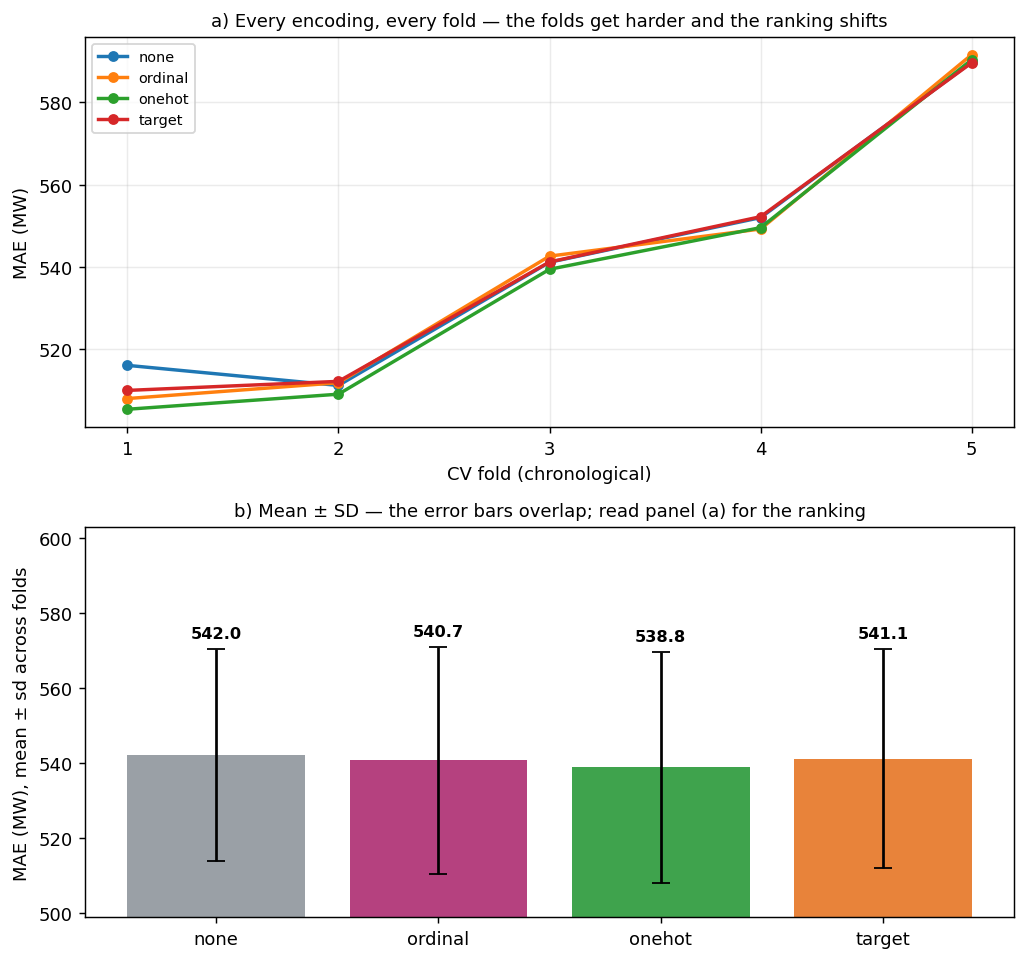

zone identity is worth 3.27 MW (none 542.05 -> onehot 538.78)
target vs ordinal :  +0.38 MW | target better in 2/5 folds
target vs onehot  :  +2.28 MW | target better in 1/5 folds

PREDICTION (2.11): target beats ordinal and roughly ties one-hot.
RESULT           : tie leg FAILED - target is worse than one-hot


In [7]:
# WHAT: four pipelines differing ONLY in the encode step, scored under one CV.
# WHY:  the plan asks for three encodings compared rather than assumed. The fourth
#       arm - no zone information at all - is the control that makes the other
#       three readable: without it, a small gap between encodings could mean they
#       are equivalent OR that zone identity is worthless. It separates those.
# NOTE: the prediction is written down in 2.11 (later in this notebook, beside the
#       encoder figures) -- "target encoding beats ordinal and roughly ties one-hot".
#       The printed RESULT line checks only the tie leg; the "target vs ordinal"
#       line above it is the beat leg.
ENCODINGS = ["none", "ordinal", "onehot", "target"]
enc_scores = {}
for e in ENCODINGS:
    pe = P.make_supervised_pipeline(lags=lags, encoding=e)
    enc_scores[e] = -cross_val_score(pe, df, y, cv=cv, scoring="neg_mean_absolute_error")

enc_tab = pd.DataFrame({
    "MAE mean": {e: s.mean() for e, s in enc_scores.items()},
    "MAE sd":   {e: s.std() for e, s in enc_scores.items()},
    "vs no-zone": {e: s.mean() - enc_scores["none"].mean() for e, s in enc_scores.items()},
}).loc[ENCODINGS]
display(enc_tab.round(2))

fig, axes = plt.subplots(2, 1, figsize=(8.0, 7.5))
ax = axes[0]
for e in ENCODINGS:
    ax.plot(range(1, len(enc_scores[e]) + 1), enc_scores[e], "o-", lw=1.9, ms=5, label=e)
ax.set_xlabel("CV fold (chronological)"); ax.set_ylabel("MAE (MW)")
ax.set_title("a) Every encoding, every fold — the folds get harder and the ranking shifts",
             fontsize=10)
ax.set_xticks(range(1, len(enc_scores["none"]) + 1)); ax.legend(fontsize=8); ax.grid(alpha=0.25)

ax = axes[1]
xs = np.arange(len(ENCODINGS))
means = [enc_scores[e].mean() for e in ENCODINGS]
sds = [enc_scores[e].std() for e in ENCODINGS]
cols = ["#9aa0a6", "#b5417f", "#3fa34d", "#e8833a"]
ax.bar(xs, means, yerr=sds, capsize=5, color=cols)
for i, (m, s) in enumerate(zip(means, sds)):
    ax.text(i, m + s + 3, f"{m:.1f}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(xs); ax.set_xticklabels(ENCODINGS)
ax.set_ylim(min(means) - 40, max(means) + max(sds) + 30)
ax.set_ylabel("MAE (MW), mean ± sd across folds")
ax.set_title("b) Mean ± SD — the error bars overlap; read panel (a) for the ranking",
             fontsize=10)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_encoding_comparison.png", bbox_inches="tight")
plt.show()

best = min(ENCODINGS[1:], key=lambda e: enc_scores[e].mean())
print(f"zone identity is worth {enc_scores['none'].mean() - enc_scores[best].mean():.2f} MW "
      f"(none {enc_scores['none'].mean():.2f} -> {best} {enc_scores[best].mean():.2f})")
for e in ("ordinal", "onehot"):
    d = enc_scores["target"] - enc_scores[e]
    print(f"target vs {e:8s}: {d.mean():+6.2f} MW | target better in {(d < 0).sum()}/{len(d)} folds")
print("\nPREDICTION (2.11): target beats ordinal and roughly ties one-hot.")
print("RESULT           : " + ("tie leg held (target <= one-hot); beat leg: see target vs ordinal above"
                               if enc_scores["target"].mean() <= enc_scores["onehot"].mean()
                               else "tie leg FAILED - target is worse than one-hot"))

**What I see:** The four arms are a wash. One-hot **538.78 MW**, ordinal **540.67**, target **541.06**, none **542.05**: a spread of 3.3 MW against a fold SD near 30. The 2.11 prediction (target beats ordinal and roughly ties one-hot) failed: target is +2.28 MW worse than one-hot (better in 1 of 5 folds) and +0.38 MW worse than ordinal (better in 2 of 5).

**What it means:** With fifteen weather columns and the per-zone relative family, the model can already tell zones apart, so an explicit zone column adds little. The encoding choice is not a real modelling decision on this feature set.

**What I do:** Ship one-hot on non-score grounds: six columns, no false order, zone identity kept. Ordinal is rejected because a small edge inside fold noise does not justify a false order. So the leakage test in §2.5 was run on an encoder I then did not ship.


In [8]:
R.save('nb02', dict(cv_mae_folds=sc.tolist(), cv_mae_mean=float(sc.mean()),
                      leaked_mae_mean=float(sc_leaky.mean()),
                      unencoded_mae_mean=float(sc_none.mean()),
                      encoding_value_mw=float(sc_none.mean() - sc.mean()),
                      leakage_optimism_mw=float(sc.mean() - sc_leaky.mean()),
                      lags=list(lags)))
print('notebook 02 complete')

[results read-only] nb02: 7 key(s) verified against the ledger, nothing written
notebook 02 complete


---

## 2.8 — Feature-engineering audit: the five standard steps

Sections 2.8–2.16 check the five standard steps (impute, encode, transform/scale, create, select) against `src/features.py` on the development block. They are diagnostics: they fit no model and write nothing to `results.json`. The audit found one real defect, the fuel-mix columns (§2.15), now excluded via `cfg.REALISED_GENERATION_COLS` and enforced by `tests/test_leakage.py`. The checklist assumes exchangeable rows; this panel is a time series, so the history buffer and the timestamp split (2.4–2.6) have no counterpart in it.


In [9]:
# Audit setup. Self-contained on purpose: this block re-derives what it needs, so
# it runs whether or not the cells above have been executed in this kernel.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

from src import config as cfg
from src import features as P
from src import results as R

plt.rcParams.update({"figure.dpi": cfg.DPI, "font.size": 9, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, ACC, BAD, GOOD = "#22223b", "#3a7ca5", "#c1121f", "#2a9d8f"

panel = pd.read_parquet(cfg.PANEL).sort_values([cfg.TIME_COL, cfg.GROUP_COL])
manifest = json.loads(cfg.MANIFEST.read_text(encoding="utf-8"))

# The audit is computed on the DEVELOPMENT block only. The holdout is not touched
# here: a diagnostic that looked at it would make the notebook 04 holdout no longer blind.
cut = cfg.HOLDOUT_CUT
dev = panel[panel[cfg.TIME_COL] <= cut]

# A REDUCED version of the matrix the pipeline hands its `select` step: calendar,
# lags and the target encoder only, in pipeline order. The relative, weather, swap
# and derive steps are skipped and the encoder is the rejected target encoder, so
# this audit sees fewer candidates (printed below) than the 69 the shipped selector
# sees in 2.18-2.22.
featured = P.GroupLagFeatures(lags=cfg.LAGS).fit(dev).transform(
    P.CalendarFeatures().fit(dev).transform(dev))
featured = P.SmoothedTargetEncoder().fit(featured, dev[cfg.TARGET]).transform(featured)
CANDS = P.MutualInfoSelector(k="all")._candidates(featured)

FUELS = ["coal", "gas", "nuclear", "oil", "other", "hydro",
         "battery", "unknown_storage", "solar_battery"]

print(f"panel      {len(panel):,} rows   dev {len(dev):,}   holdout {len(panel)-len(dev):,}")
print(f"lags       {cfg.LAGS}   rolling {cfg.ROLL_WINDOWS}")
print(f"candidates the selector would consider: {len(CANDS)}")

panel      315,485 rows   dev 268,186   holdout 47,299
lags       (1, 2, 3, 24, 168)   rolling (24, 168)
candidates the selector would consider: 51


### 2.9 — Which steps fit something

The figure shows six of the pipeline's eleven steps, what each learns from the training fold, and (in red) what leaks if it is fitted on the full panel.


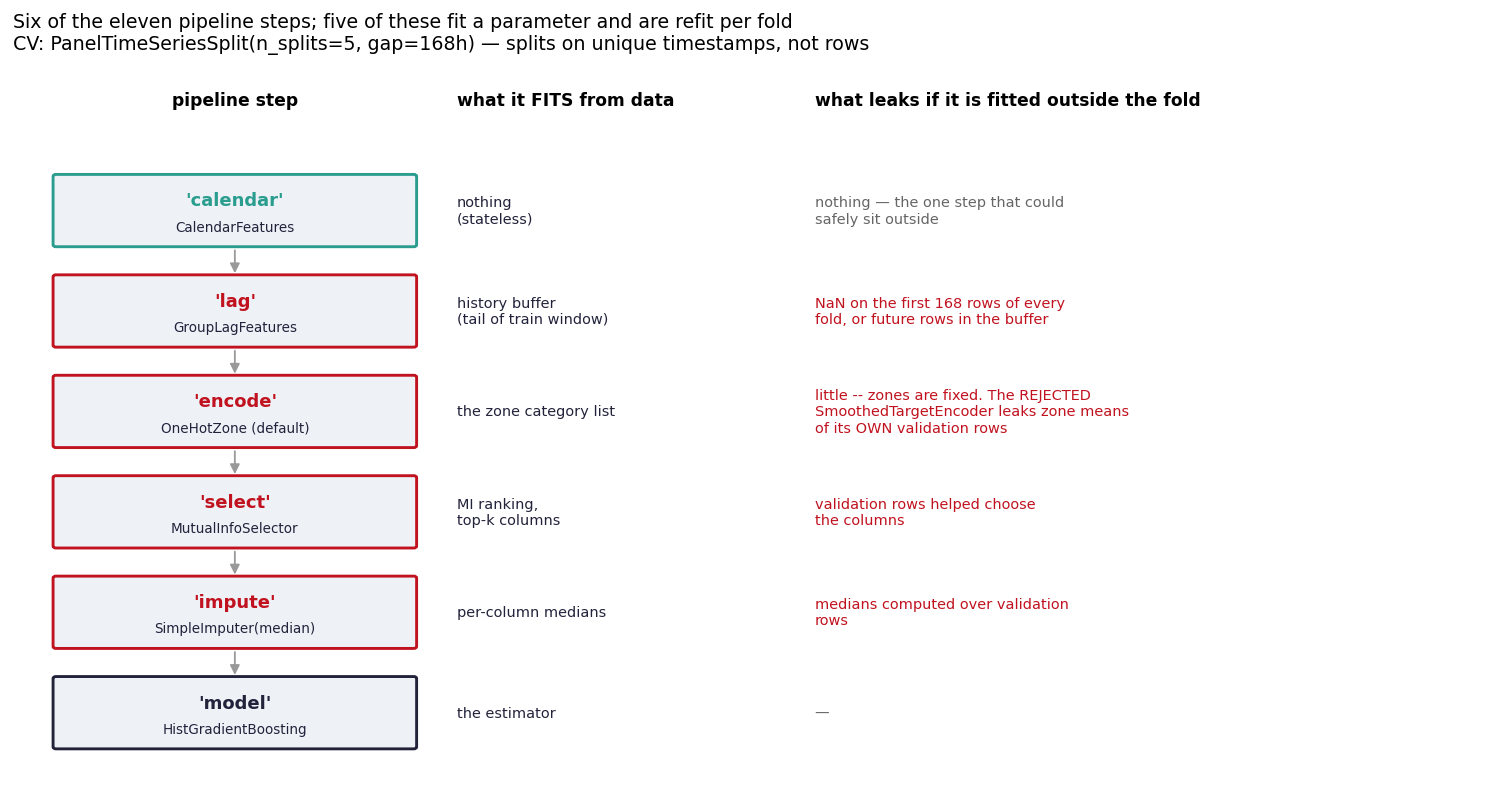

step names are contractual — the notebooks reach for them:
  ['calendar', 'lag', 'relative', 'weather', 'swap', 'derive', 'encode', 'ablate', 'select', 'impute', 'model']


In [10]:
steps = [
    ("calendar", "CalendarFeatures", "nothing\n(stateless)",
     "nothing — the one step that could\nsafely sit outside", GOOD),
    ("lag", "GroupLagFeatures", "history buffer\n(tail of train window)",
     "NaN on the first 168 rows of every\nfold, or future rows in the buffer", BAD),
    # OneHotZone has been the shipped default since 2026-08-13, chosen in 2.7 on
    # non-score grounds (see the target-vs-one-hot line printed below).
    # The rejected encoder stays in the leak column because its failure mode is
    # the exam question this map answers.
    ("encode", "OneHotZone (default)", "the zone category list",
     "little -- zones are fixed. The REJECTED\n"
     "SmoothedTargetEncoder leaks zone means\nof its OWN validation rows", BAD),
    ("select", "MutualInfoSelector", "MI ranking,\ntop-k columns",
     "validation rows helped choose\nthe columns", BAD),
    ("impute", "SimpleImputer(median)", "per-column medians",
     "medians computed over validation\nrows", BAD),
    ("model", "HistGradientBoosting", "the estimator", "—", INK),
]
fig, ax = plt.subplots(figsize=(11.5, 6.2)); ax.set_axis_off()
y = 6
for name, cls, fits, leak, col in steps:
    ax.add_patch(FancyBboxPatch((0.3, y - .34), 2.5, .68, boxstyle="round,pad=0.02",
                                fc="#eef2f7", ec=col, lw=1.6))
    ax.text(1.55, y + .1, f"'{name}'", ha="center", va="center", fontsize=10,
            fontweight="bold", color=col)
    ax.text(1.55, y - .16, cls, ha="center", va="center", fontsize=7.5, color=INK)
    ax.text(3.1, y, fits, va="center", fontsize=8, color=INK)
    ax.text(5.6, y, leak, va="center", fontsize=8, color=col if col == BAD else "#666")
    if y > 1:
        ax.add_patch(FancyArrowPatch((1.55, y - .36), (1.55, y - .66),
                                     arrowstyle="-|>", mutation_scale=11, color="#999"))
    y -= 1
ax.text(1.55, 7.05, "pipeline step", ha="center", fontweight="bold", fontsize=9.5)
ax.text(3.1, 7.05, "what it FITS from data", fontweight="bold", fontsize=9.5)
ax.text(5.6, 7.05, "what leaks if it is fitted outside the fold", fontweight="bold", fontsize=9.5)
ax.set_xlim(0, 10.2); ax.set_ylim(0.3, 7.5)
ax.set_title("Six of the eleven pipeline steps; five of these fit a parameter and are refit per fold\n"
             f"CV: PanelTimeSeriesSplit(n_splits={cfg.N_SPLITS}, gap={cfg.CV_GAP}h) "
             "— splits on unique timestamps, not rows", fontsize=10.5, loc="left")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_pipeline_map.png"); plt.show()

print("step names are contractual — the notebooks reach for them:")
print(" ", [n for n, _ in P.make_supervised_pipeline().steps])

**What I see:** `calendar` fits nothing; it is a pure function of the timestamp. The others learn something from the training fold: the lag history buffer, the zone category list, the MI ranking (over 69 columns on the shipped pipeline), per-column medians, and the model. Of the steps not drawn, `derive` also fits (a per zone-month-hour irradiance ceiling for `SolarClearSkyIndex`) and is refit per fold.

**What I do:** Keep every step inside the Pipeline, `calendar` included, so there is one definition of `hour` everywhere. `tests/test_leakage.py` asserts this.


### 2.10 — Step 1 — imputation

Two layers: notebook 01 interpolates gaps ≤ 3 h, and the pipeline then applies `SimpleImputer(median)`. Median, not mean, because the raw data held outliers such as SWPP reporting 3,621,097 MW of demand. Panel (a) shows what interpolation repaired; panel (b) shows whether the remaining missingness is random or blocked by zone.


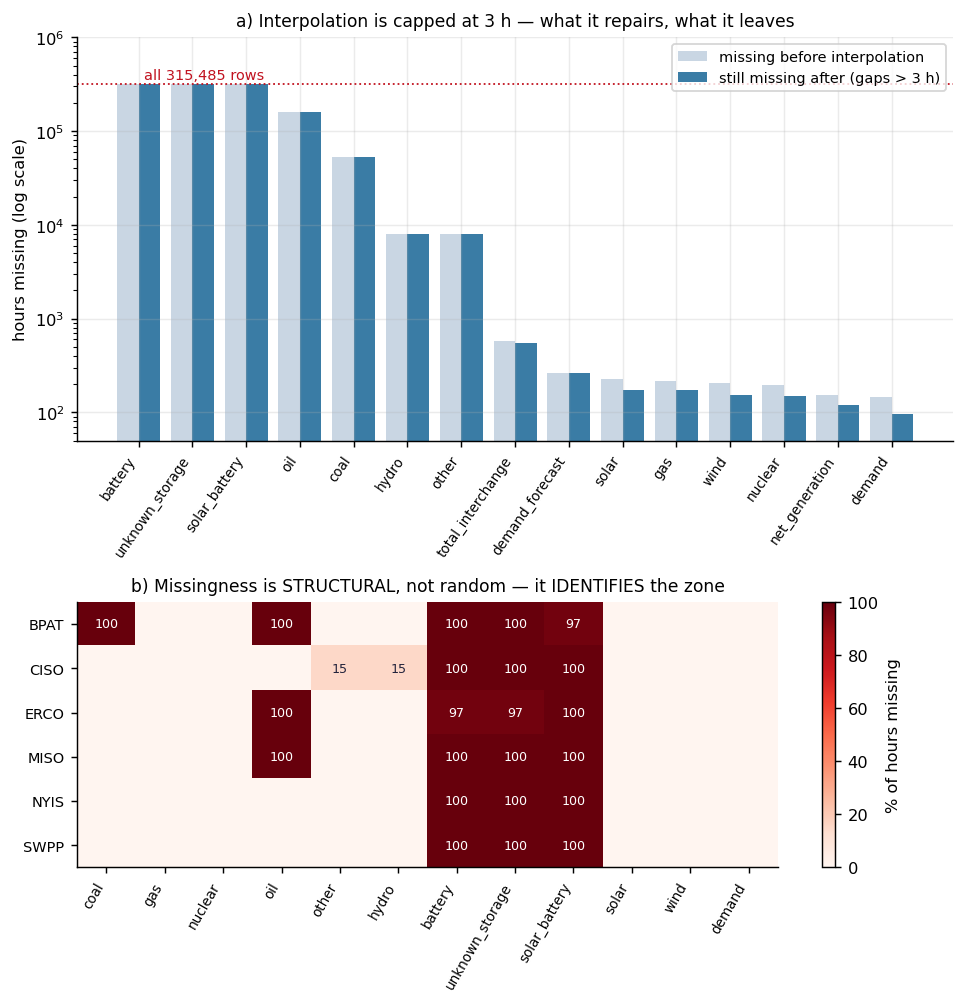

rows dropped for an unrecoverable target : 163
`coal` still missing after interpolation : 52,717 h (16.7% of the panel)

zones reporting NOTHING for a column (100% missing):
  coal             ['BPAT']
  oil              ['BPAT', 'ERCO', 'MISO']
  battery          ['BPAT', 'CISO', 'MISO', 'NYIS', 'SWPP']
  unknown_storage  ['BPAT', 'CISO', 'MISO', 'NYIS', 'SWPP']
  solar_battery    ['CISO', 'ERCO', 'MISO', 'NYIS', 'SWPP']


In [11]:
cl = manifest["cleaning"]
before, after = cl["missing_before_interp"], cl["missing_after_interp"]
cols = sorted(before, key=lambda c: -before[c])
total = manifest["rows"]

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(7.5, 7.8),
                              gridspec_kw={"height_ratios": [1.9, 1.25]})
x = np.arange(len(cols))
ax.bar(x - .2, [before[c] for c in cols], .4, label="missing before interpolation",
       color="#c9d6e3")
ax.bar(x + .2, [after.get(c, 0) for c in cols], .4,
       label="still missing after (gaps > 3 h)", color=ACC)
ax.axhline(total, color=BAD, ls=":", lw=1)
ax.text(0.1, total * 1.15, f"all {total:,} rows", color=BAD, fontsize=8)
ax.set_yscale("log"); ax.set_ylim(50, total * 3.2); ax.set_xticks(x)
ax.set_xticklabels(cols, rotation=55, ha="right", fontsize=7.5)
ax.set_ylabel("hours missing (log scale)"); ax.legend(fontsize=8, loc="upper right")
ax.set_title("a) Interpolation is capped at 3 h — what it repairs, what it leaves", fontsize=9.5)

# Structural vs random: which zone fails to report which fuel.
grid = pd.DataFrame({c: panel.groupby(cfg.GROUP_COL)[c].apply(lambda s: 100 * s.isna().mean())
                     for c in FUELS + ["solar", "wind", "demand"]})
im = ax2.imshow(grid.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax2.set_xticks(range(len(grid.columns)))
ax2.set_xticklabels(grid.columns, rotation=60, ha="right", fontsize=7.5)
ax2.set_yticks(range(len(grid.index))); ax2.set_yticklabels(grid.index, fontsize=8)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if v > 0.5:
            ax2.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                     color="white" if v > 55 else INK)
ax2.grid(False); plt.colorbar(im, ax=ax2, label="% of hours missing")
ax2.set_title("b) Missingness is STRUCTURAL, not random — it IDENTIFIES the zone", fontsize=9.5)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_imputation.png"); plt.show()

print(f"rows dropped for an unrecoverable target : {cl['rows_dropped_missing_target']}")
print(f"`coal` still missing after interpolation : {after['coal']:,} h "
      f"({100*after['coal']/total:.1f}% of the panel)")
print("\nzones reporting NOTHING for a column (100% missing):")
for c in grid.columns:
    z = [i for i in grid.index if grid.loc[i, c] > 99]
    if z:
        print(f"  {c:16s} {z}")

**What I see:** Interpolation fixes small gaps: `demand` falls 145 → 96 hours. Large gaps barely move: `coal` 52,761 → 52,717, `oil` 157,908 → 157,870. These are not gaps but fuels a zone does not report: BPAT reports no `coal`, BPAT/ERCO/MISO no `oil`, and the storage columns are empty or near-empty. Panel (b) shows solid blocks, not speckle.

**What it means:** The median imputer fills all of this with one constant, so "BPAT burns no coal" and a two-hour telemetry drop look the same. Missingness is a near-perfect zone identifier and is being erased.

**What I do:** A possible test is `SimpleImputer(add_indicator=True)`. It matters little for the raw fuel columns, which are excluded as features (§2.15).


### 2.11 — Step 2 — encoding

One-hot, ordinal and smoothed target encoding of `zone` on the development block. Panel (b) shows whether the ordinal integers track the load or the alphabet; panel (c) shows how far smoothing moves the target encoding.


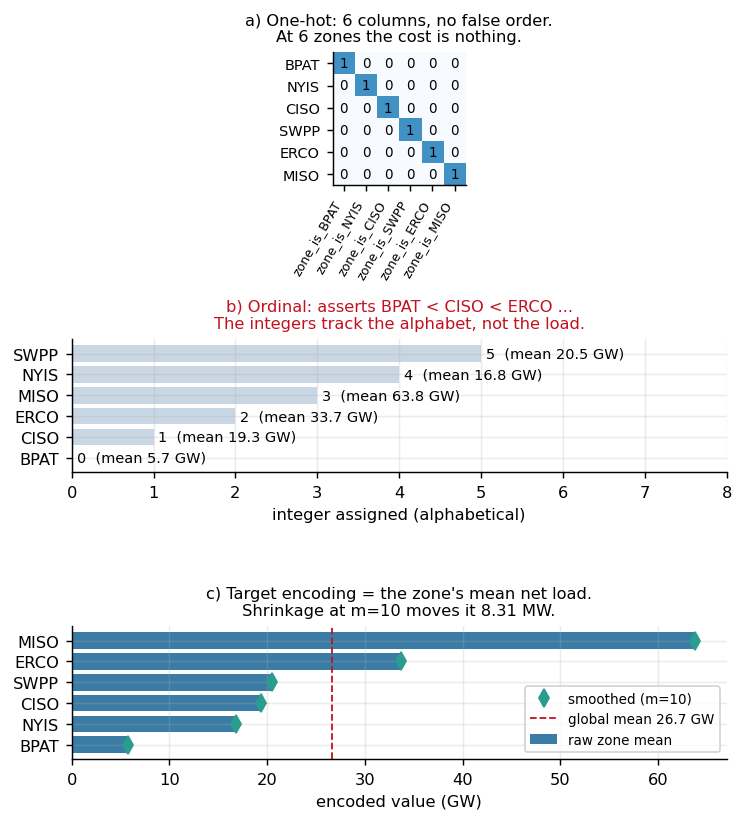

zone means on the dev block (MW):
  BPAT  n= 44,647  mean     5,711  ->  encoded     5,715
  NYIS  n= 44,695  mean    16,794  ->  encoded    16,796
  CISO  n= 44,708  mean    19,341  ->  encoded    19,343
  SWPP  n= 44,712  mean    20,523  ->  encoded    20,525
  ERCO  n= 44,712  mean    33,717  ->  encoded    33,716
  MISO  n= 44,712  mean    63,821  ->  encoded    63,813

largest shrinkage at m=10       : 8.31 MW
corr(zone_te, net_load_lag1)   : +0.9116


In [12]:
y = dev[cfg.TARGET]
zmean = y.groupby(dev[cfg.GROUP_COL]).mean().sort_values()
n = y.groupby(dev[cfg.GROUP_COL]).count()
gmean = float(y.mean())
te10 = (n * zmean + 10 * gmean) / (n + 10)          # the m=10 default
te_shift = float((te10 - zmean).abs().max())

lag1 = featured[f"{cfg.TARGET}_lag1"]; ok = lag1.notna()
r_te_lag1 = float(np.corrcoef(featured.loc[ok, "zone_te"], lag1[ok])[0, 1])

fig, axes = plt.subplots(3, 1, figsize=(5.8, 6.4))
ax = axes[0]
oh = pd.DataFrame(np.eye(6, dtype=int), index=zmean.index,
                  columns=[f"zone_is_{z}" for z in zmean.index])
ax.imshow(oh.values, cmap="Blues", vmin=0, vmax=1.6)
ax.set_xticks(range(6)); ax.set_xticklabels(oh.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(6)); ax.set_yticklabels(oh.index, fontsize=8)
for i in range(6):
    for j in range(6):
        ax.text(j, i, oh.values[i, j], ha="center", va="center", fontsize=7.5)
ax.grid(False)
ax.set_title("a) One-hot: 6 columns, no false order.\nAt 6 zones the cost is nothing.", fontsize=9)

ax = axes[1]
order = sorted(zmean.index)
ax.barh(order, range(len(order)), color="#c9d6e3")
for i, z in enumerate(order):
    ax.text(i + .06, z, f"{i}  (mean {zmean[z]/1000:.1f} GW)", va="center", fontsize=8)
ax.set_xlim(0, 8); ax.set_xlabel("integer assigned (alphabetical)")
ax.set_title("b) Ordinal: asserts BPAT < CISO < ERCO ...\nThe integers track the alphabet, not the load.",
             fontsize=9, color=BAD)

ax = axes[2]
ax.barh(zmean.index, zmean.values / 1000, color=ACC, label="raw zone mean")
ax.plot(te10.reindex(zmean.index).values / 1000, range(6), "d", color=GOOD, ms=7,
        label="smoothed (m=10)")
ax.axvline(gmean / 1000, color=BAD, ls="--", lw=1, label=f"global mean {gmean/1000:.1f} GW")
ax.set_xlabel("encoded value (GW)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title(f"c) Target encoding = the zone's mean net load.\n"
             f"Shrinkage at m=10 moves it {te_shift:.2f} MW.", fontsize=9)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_encodings.png"); plt.show()

print("zone means on the dev block (MW):")
for z, v in zmean.items():
    print(f"  {z}  n={n[z]:>7,}  mean {v:>9,.0f}  ->  encoded {te10[z]:>9,.0f}")
print(f"\nlargest shrinkage at m=10       : {te_shift:.2f} MW")
print(f"corr(zone_te, net_load_lag1)   : {r_te_lag1:+.4f}")

**What I see:** One-hot costs six columns. Ordinal assigns BPAT=0 (5.7 GW), CISO=1 (19.3 GW), ERCO=2 (33.7 GW), MISO=3 (63.8 GW), NYIS=4 (16.8 GW), SWPP=5 (20.5 GW): it follows the alphabet and breaks order at NYIS. Smoothing at m=10 moves the encoding by at most 8.31 MW. `corr(zone_te, net_load_lag1) = +0.91`.

**What it means:** Ordinal asserts an order the data contradicts. With 44,000+ rows per zone, the smoothing parameter cannot matter, so it is not tuned. At +0.91 with `lag1`, target encoding mostly repeats a level the model already has.

**What I do:** Score all three in 2.7, with the prediction written first: target beats ordinal and roughly ties one-hot.


### 2.12 — Step 3 — transformation and scaling

Two checks: is a log transform of the target admissible, and does the model need a scaler?


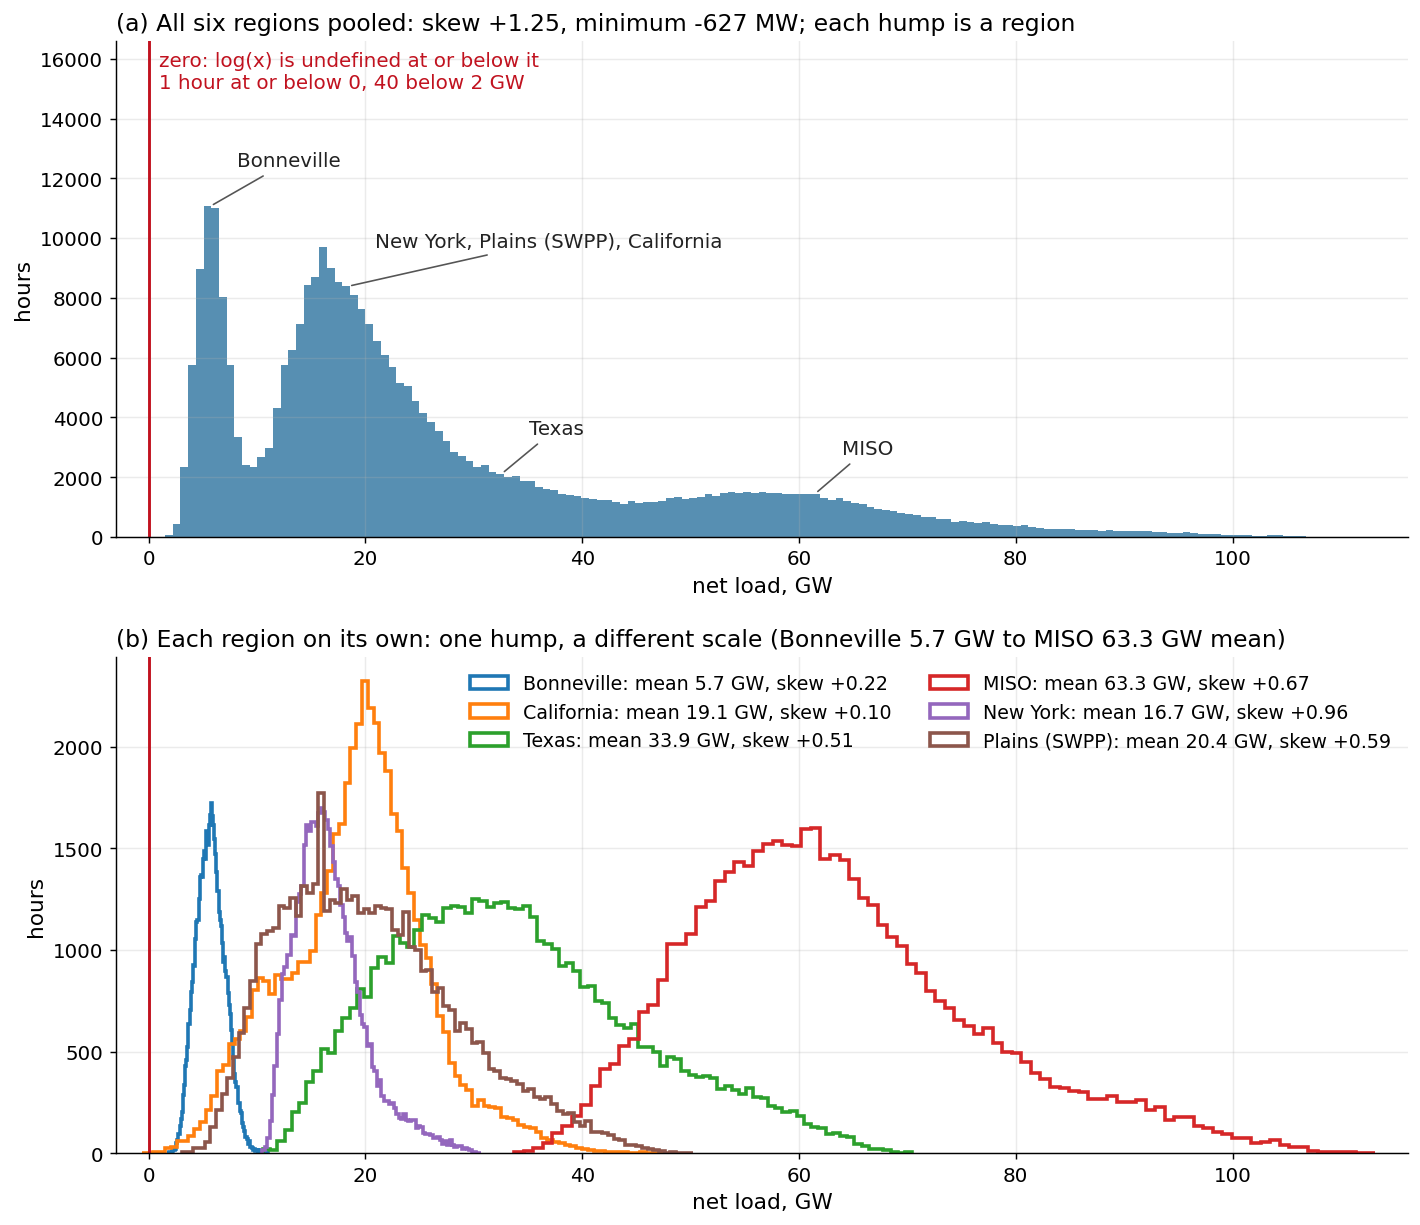

skew +1.246 · min -627 MW · hours <= 0: 1 · hours < 2,000 MW: 40
a log transform of the target is INADMISSIBLE, not merely unhelpful.

per zone: mean and median net load (GW), skew
  BPAT  Bonneville     mean   5.7  median   5.7  skew +0.22
  NYIS  New York       mean  16.7  median  16.3  skew +0.96
  CISO  California     mean  19.1  median  19.5  skew +0.10
  SWPP  Plains (SWPP)  mean  20.4  median  19.4  skew +0.59
  ERCO  Texas          mean  33.9  median  32.6  skew +0.51
  MISO  MISO           mean  63.3  median  61.5  skew +0.67


In [13]:
# WHAT: the target's distribution, pooled and per zone, and whether a log transform is admissible.
# WHY:  a skew of +1.25 is the checklist's trigger for log(y); panel (b) shows what the skew is made
#       of, and the zero line in (a) shows why the log is not an option at all.
# Drawn at the size the final report shows it: GW on the axis, the region behind each hump of the
# pooled histogram named on it, and panel (b) in the report's region names and colours.
y_all = panel[cfg.TARGET]
skew, ymin = float(y_all.skew()), float(y_all.min())
n_le0, n_lo = int((y_all <= 0).sum()), int((y_all < 2000).sum())

ZONE_NAME = {"CISO": "California", "ERCO": "Texas", "MISO": "MISO", "SWPP": "Plains (SWPP)",
             "BPAT": "Bonneville", "NYIS": "New York"}
ZONE_COLOR = {"CISO": "#ff7f0e", "ERCO": "#2ca02c", "MISO": "#d62728", "SWPP": "#8c564b",
              "BPAT": "#1f77b4", "NYIS": "#9467bd"}
zm = panel.groupby(cfg.GROUP_COL)[cfg.TARGET].mean()
zmed = panel.groupby(cfg.GROUP_COL)[cfg.TARGET].median()
zskew = panel.groupby(cfg.GROUP_COL)[cfg.TARGET].skew()

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 9.5))
counts, edges, _ = ax.hist(y_all / 1000, bins=160, color=ACC, alpha=.85)
ax.axvline(0, color=BAD, lw=1.6)
ax.set_ylim(0, counts.max() * 1.5)
ax.text(1.0, counts.max() * 1.47,
        f"zero: log(x) is undefined at or below it\n{n_le0} hour at or below 0, {n_lo} below 2 GW",
        color=BAD, fontsize=11, va="top")
# name the region behind each hump: regions whose medians are within 6 GW share one label
order = zmed.sort_values()
groups, cur = [], [order.index[0]]
for z in order.index[1:]:
    if zmed[z] - zmed[cur[-1]] <= 6000:
        cur.append(z)
    else:
        groups.append(cur); cur = [z]
groups.append(cur)
for g in groups:
    x = float(np.mean([zmed[z] for z in g])) / 1000
    h = counts[min(np.searchsorted(edges, x) - 1, len(counts) - 1)]
    ax.annotate(", ".join(ZONE_NAME[z] for z in g), xy=(x, h), xytext=(x + 2.5, h + counts.max() * .12),
                fontsize=11, color="#222", arrowprops=dict(arrowstyle="-", color="#555", lw=0.9))
ax.set_xlabel("net load, GW", fontsize=12); ax.set_ylabel("hours", fontsize=12)
ax.tick_params(labelsize=11)
ax.set_title(f"(a) All six regions pooled: skew {skew:+.2f}, minimum {ymin:,.0f} MW; "
             "each hump is a region", fontsize=13, loc="left")

for z, g in panel.groupby(cfg.GROUP_COL):
    ax2.hist(g[cfg.TARGET] / 1000, bins=90, histtype="step", lw=2, color=ZONE_COLOR.get(z),
             label=f"{ZONE_NAME.get(z, z)}: mean {zm[z] / 1000:.1f} GW, skew {zskew[z]:+.2f}")
ax2.axvline(0, color=BAD, lw=1.6)
ax2.set_xlabel("net load, GW", fontsize=12); ax2.set_ylabel("hours", fontsize=12)
ax2.tick_params(labelsize=11)
ax2.legend(fontsize=10.5, ncol=2, loc="upper right", frameon=False)
ax2.set_title(f"(b) Each region on its own: one hump, a different scale "
              f"({ZONE_NAME[zm.idxmin()]} {zm.min() / 1000:.1f} GW to {ZONE_NAME[zm.idxmax()]} "
              f"{zm.max() / 1000:.1f} GW mean)", fontsize=13, loc="left")
for a in (ax, ax2):
    a.set_xlim(min(-3, ymin / 1000 - 1), y_all.max() / 1000 + 3)
    a.grid(alpha=0.25, axis="x")
plt.tight_layout(h_pad=2.0); plt.savefig(cfg.FIGURES / "02_log_transform.png"); plt.show()

print(f"skew {skew:+.3f} · min {ymin:,.0f} MW · hours <= 0: {n_le0} · hours < 2,000 MW: {n_lo}")
print("a log transform of the target is INADMISSIBLE, not merely unhelpful.")
print("\nper zone: mean and median net load (GW), skew")
for z in zm.sort_values().index:
    print(f"  {z}  {ZONE_NAME.get(z, z):14s} mean {zm[z] / 1000:5.1f}  median {zmed[z] / 1000:5.1f}  "
          f"skew {zskew[z]:+.2f}")

**What I see:** Pooled skew is +1.25, but the minimum is −627 MW, one hour is at or below zero and 40 hours are below 2,000 MW. Panel (b) shows the skew comes from six roughly unimodal zones at different scales (BPAT 5.7 GW to MISO 63.3 GW), not one long tail.

**What it means:** `log(x)` is undefined on this target, and the hours it fails on (low and negative net load) are the ones this project studies. The skew is between-zone scale, which `zone` and a scale-free tree already handle.

**What I do:** No log transform. If a variance-stabilising transform is ever needed, `asinh` works on negatives.


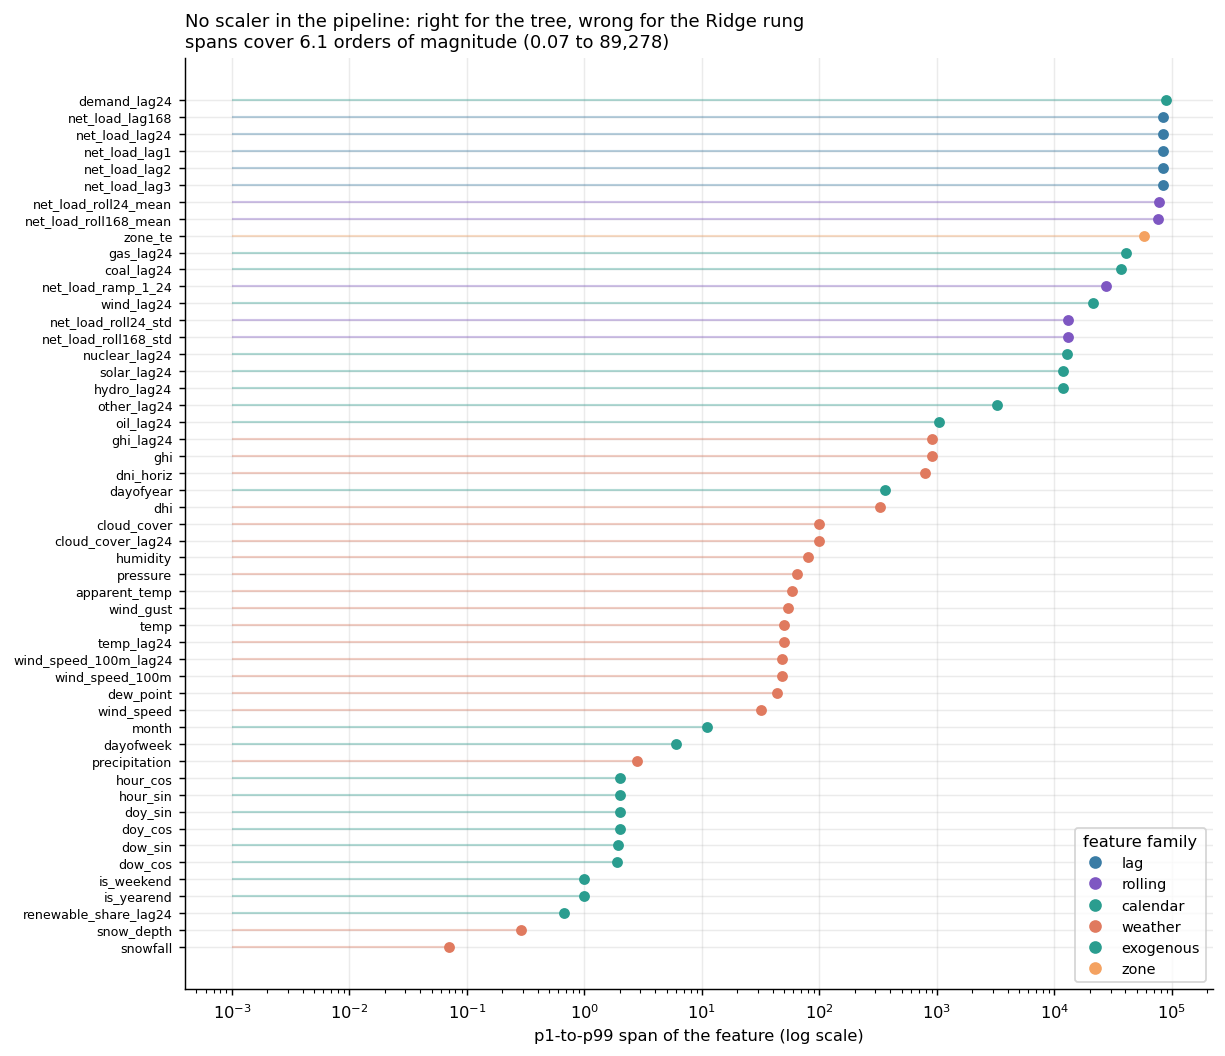

widest  demand_lag24             span     89,278.0
narrowest snowfall               span        0.070
ratio: 1,275,400x

steps in make_supervised_pipeline(): ['calendar', 'lag', 'relative', 'weather', 'swap', 'derive', 'encode', 'ablate', 'select', 'impute', 'model']
-> there is no 'scale' step. HistGradientBoosting does not care. Ridge does.


In [14]:
sub = featured[CANDS].select_dtypes(include=[np.number])
rng = (pd.DataFrame({"span": sub.quantile(.99) - sub.quantile(.01)})
       .dropna().sort_values("span"))
orders = float(np.log10(rng["span"].max() / rng["span"][rng["span"] > 0].min()))

fig, ax = plt.subplots(figsize=(9.5, 8.2))
# `renewables` was missing here and this cell raised KeyError on every run from
# fca5191 until 2026-08-21. That commit split the renewable columns out of
# "other" in `P.feature_family` -- the fix for the ordering bug that had made
# cloud_cover, humidity and wind_speed invisible to notebook 04's ablation -- and
# nothing pointed at the notebooks that hardcode a family list.
fam_col = {"lag": ACC, "rolling": "#7e57c2", "calendar": GOOD,
           "weather": "#e07a5f", "exogenous": "#2a9d8f", "renewables": "#2a9d8f",
           "zone": "#f4a261", "other": "#888"}

# CHECKED UP FRONT, and the check is the actual repair. A hardcoded map that
# mirrors a function in src/ will drift again the next time a family is added;
# what must not happen again is learning about it from a KeyError raised inside a
# plotting loop after the cell has already done its work. Asking `feature_family`
# what it returns for THESE columns, before drawing anything, turns that into one
# sentence naming the family nobody coloured.
_families = {P.feature_family(n) for n in rng.index}
_uncoloured = _families - set(fam_col)
assert not _uncoloured, (
    f"P.feature_family returns {sorted(_uncoloured)}, which this figure has no "
    f"colour for. Add it to fam_col -- see src/features.py feature_family().")

for i, (name, r) in enumerate(rng.iterrows()):
    c = fam_col[P.feature_family(name)]
    ax.plot([max(r["span"], 1e-3)], [i], "o", color=c, ms=5)
    ax.hlines(i, 1e-3, max(r["span"], 1e-3), color=c, alpha=.35, lw=1.2)
ax.set_xscale("log"); ax.set_yticks(range(len(rng)))
ax.set_yticklabels(rng.index, fontsize=7)
ax.set_xlabel("p1-to-p99 span of the feature (log scale)")
for lbl, c in fam_col.items():
    if lbl in _families:          # no legend entry for a family with no columns
        ax.plot([], [], "o", color=c, label=lbl)
ax.legend(fontsize=8, title="feature family", loc="lower right")
ax.set_title("No scaler in the pipeline: right for the tree, wrong for the Ridge rung\n"
             f"spans cover {orders:.1f} orders of magnitude "
             f"({rng['span'].min():.2g} to {rng['span'].max():,.0f})", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_scaling.png"); plt.show()

print(f"widest  {rng.index[-1]:24s} span {rng['span'].iloc[-1]:>12,.1f}")
print(f"narrowest {rng.index[0]:22s} span {rng['span'].iloc[0]:>12,.3f}")
print(f"ratio: {rng['span'].max()/rng['span'].min():,.0f}x")
print("\nsteps in make_supervised_pipeline():", [n for n, _ in P.make_supervised_pipeline().steps])
print("-> there is no 'scale' step. HistGradientBoosting does not care. Ridge does.")

**What I see:** Feature spans (p1–p99) run from 0.070 (`snowfall`) to 89,278 (`demand_lag24`), a ratio near 1,275,000×. Lags and rolling means sit near 10⁵, calendar cyclicals at 2, weather mostly in the tens.

**What it means:** For `HistGradientBoostingRegressor` this does not matter: trees split on order. For Ridge it does: an L2 penalty is not scale-invariant, so small-span features like `hour_sin` would be effectively removed from a linear model.

**What I do:** The shared pipeline has no scaler and the tree does not need one. Notebook 04 fits `StandardScaler` + `Ridge` as its own pipeline.


### 2.13 — Step 4 — feature creation: cyclical time

Hour 23 and hour 0 are one hour apart but 23 apart as integers. Panel (a) is the diurnal profile, (b) the jump raw hour creates, (c) the sin/cos encoding that removes it.


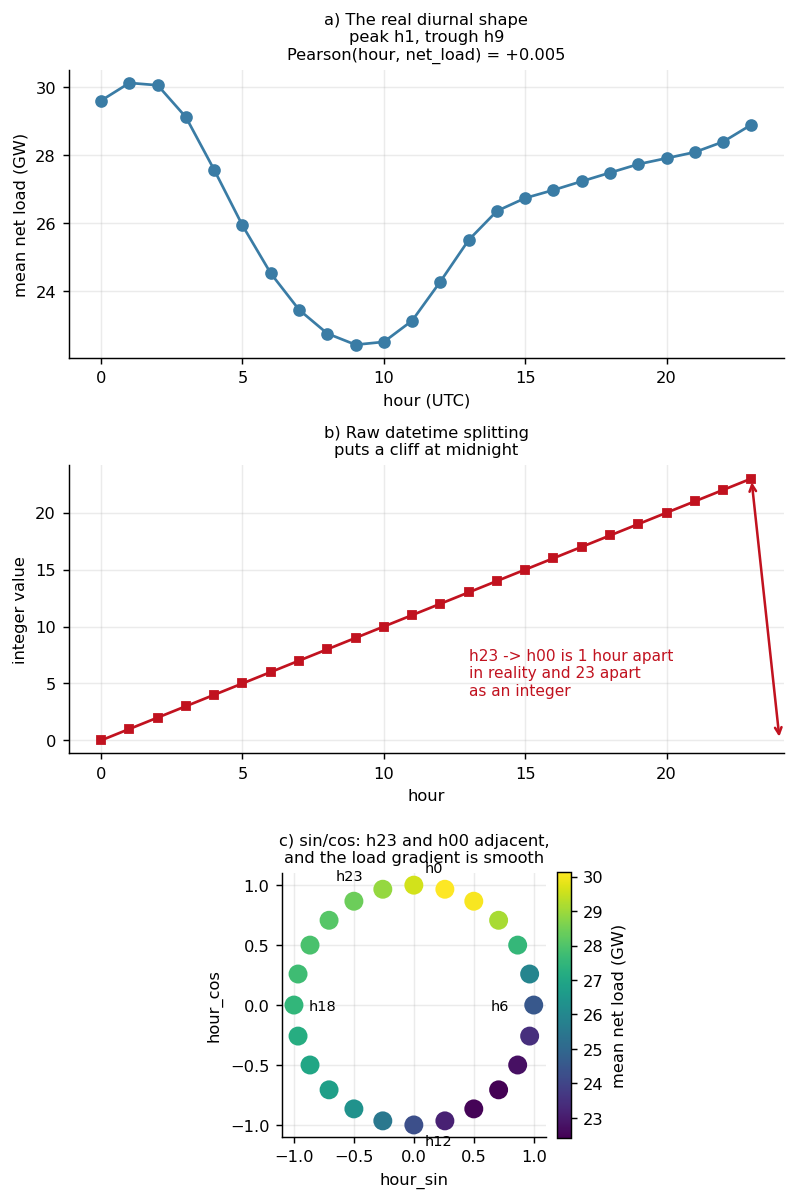

CalendarFeatures creates 12 columns: ['hour', 'dayofweek', 'month', 'dayofyear', 'is_weekend', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'is_yearend']

Pearson(hour, net_load) = +0.0047  <- a correlation filter would DELETE the hour
pooled diurnal swing: 7,708 MW (29% of the mean)


In [15]:
prof = panel.groupby(panel[cfg.TIME_COL].dt.hour)[cfg.TARGET].mean()
r_hour = float(np.corrcoef(panel[cfg.TIME_COL].dt.hour, panel[cfg.TARGET])[0, 1])

# Panel (c) gets the middle column of its row, so the square box is centred
# instead of pushed against the colourbar on the right.
fig = plt.figure(figsize=(6.2, 9.4))
_gs = fig.add_gridspec(3, 3, width_ratios=[1, 2.4, 1])
ax1 = fig.add_subplot(_gs[0, :])
ax1.plot(prof.index, prof.values / 1000, "o-", color=ACC)
ax1.set_xlabel("hour (UTC)"); ax1.set_ylabel("mean net load (GW)")
ax1.set_title(f"a) The real diurnal shape\npeak h{prof.idxmax()}, trough h{prof.idxmin()}\n"
              f"Pearson(hour, net_load) = {r_hour:+.3f}", fontsize=9)

ax2 = fig.add_subplot(_gs[1, :])
ax2.plot(range(24), range(24), "s-", color=BAD, ms=4)
ax2.annotate("", xy=(23, 23), xytext=(24, 0),
             arrowprops=dict(arrowstyle="<->", color=BAD, lw=1.4))
ax2.text(13, 4, "h23 -> h00 is 1 hour apart\nin reality and 23 apart\nas an integer",
         color=BAD, fontsize=8.5)
ax2.set_xlabel("hour"); ax2.set_ylabel("integer value")
ax2.set_title("b) Raw datetime splitting\nputs a cliff at midnight", fontsize=9)

ax3 = fig.add_subplot(_gs[2, 1])
th = 2 * np.pi * np.arange(24) / 24
sc = ax3.scatter(np.sin(th), np.cos(th), c=prof.values / 1000, cmap="viridis", s=90, zorder=3)
for h, off in {0: (6, 7), 6: (-24, -3), 12: (6, -11), 18: (8, -3), 23: (-26, 5)}.items():
    ax3.annotate(f"h{h}", (np.sin(th[h]), np.cos(th[h])),
                 textcoords="offset points", xytext=off, fontsize=8)
# A square BOX rather than set_aspect("equal"): the latter shrank the panel to a
# small circle pushed to the right of an otherwise empty row.
ax3.set_box_aspect(1); ax3.set_xlabel("hour_sin"); ax3.set_ylabel("hour_cos")
plt.colorbar(sc, ax=ax3, label="mean net load (GW)", fraction=0.046, pad=0.04)
ax3.set_title("c) sin/cos: h23 and h00 adjacent,\nand the load gradient is smooth", fontsize=9)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_cyclical.png"); plt.show()

made = [c for c in P.CalendarFeatures().fit(dev).transform(dev.head(48)).columns
        if c not in dev.columns]
print(f"CalendarFeatures creates {len(made)} columns: {made}")
print(f"\nPearson(hour, net_load) = {r_hour:+.4f}  <- a correlation filter would DELETE the hour")
print(f"pooled diurnal swing: {prof.max()-prof.min():,.0f} MW "
      f"({100*(prof.max()-prof.min())/prof.mean():.0f}% of the mean)")

**What I see:** The pooled diurnal swing is 7,708 MW, about 29% of the mean, yet `Pearson(hour, net_load) = +0.005`. Raw hour jumps 23 units at midnight; the sin/cos pair forms a closed ring with h23 next to h00. `CalendarFeatures` produces 12 columns; raw `hour` is then dropped by `DROP_ALWAYS` as a duplicate of the cyclical pair.

**What it means:** A correlation filter would delete the strongest periodic pattern in the data, because the relation is cyclical, not linear. The sin/cos pair removes a discontinuity that a linear model reads as a cliff.

**What I do:** Keep the cyclical encoding. `is_yearend` is only a proxy for holidays; the `holidays` package would be the upgrade. Possible interactions: `temp × hour`.


### 2.14 — Step 5 — selection: mutual information vs correlation

`MutualInfoSelector` is justified in its docstring by the claim that hour-of-day has near-zero correlation but high predictive value. Panel (a) compares MI with |Pearson r|, (b) shows what `k=12` would keep, (c) shows the effect of pooling zones across time zones.


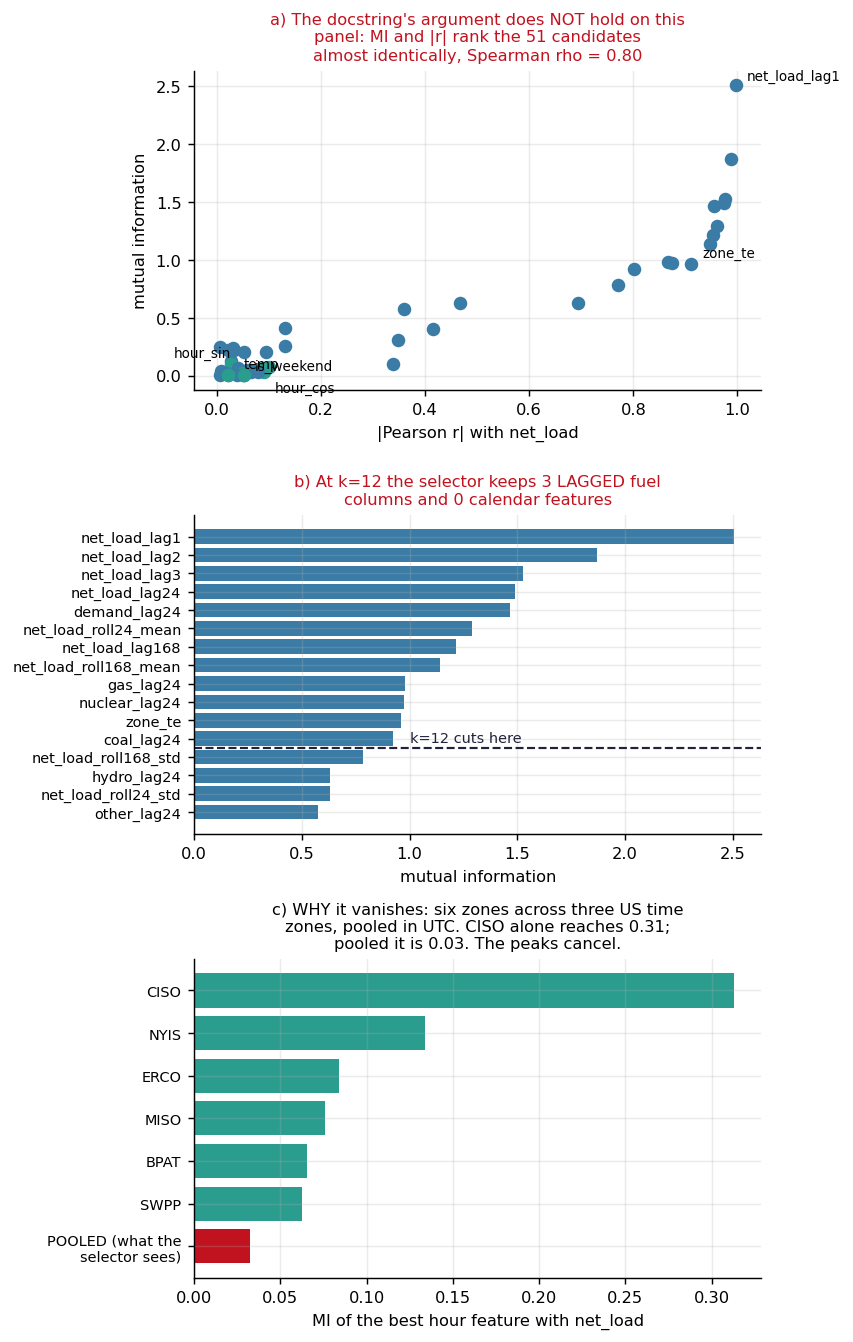

MI of the best hour feature with net_load: CISO alone 0.31, pooled over the six zones 0.03


k=12 would select:
   net_load_lag1
   net_load_lag2
   net_load_lag3
   net_load_lag24
   net_load_lag168
   demand_lag24
   coal_lag24
   gas_lag24
   nuclear_lag24
   net_load_roll24_mean
   net_load_roll168_mean
   zone_te

calendar features surviving k=12: NONE

hour_sin: |r| = 0.048, MI = 0.019, MI rank 44 of 51
Spearman(MI, |r|) across all candidates = 0.803


In [16]:
from sklearn.feature_selection import mutual_info_regression
from scipy.stats import spearmanr

X = featured[CANDS]; yy = dev[cfg.TARGET]
# gaps filled with each column's median, as the pipeline's imputer fills them; dropping
# incomplete rows instead removed BPAT, ERCO and MISO (oil_lag24 is missing on all their rows)
Xc, yc = X.fillna(X.median()), yy
idx = np.random.RandomState(cfg.SEED).choice(len(Xc), min(20_000, len(Xc)), replace=False)
Xs, ys = Xc.iloc[idx], yc.iloc[idx]

mi = mutual_info_regression(Xs.to_numpy(), ys.to_numpy(), random_state=cfg.SEED)
absr = np.array([abs(np.corrcoef(Xs[c], ys)[0, 1]) for c in CANDS])
t = pd.DataFrame({"mi": mi, "absr": absr}, index=CANDS).sort_values("mi", ascending=False)
rho = float(spearmanr(t["mi"], t["absr"]).statistic)

LEAKY = set(FUELS) | {"renewable_share"}
CAL = ("hour", "dow", "doy", "month", "is_")
def colour(nm):
    return BAD if nm in LEAKY else (GOOD if nm.startswith(CAL) else ACC)

fig = plt.figure(figsize=(6.6, 10.4))
ax = fig.add_subplot(3, 1, 1)
for nm, r in t.iterrows():
    ax.scatter(r["absr"], r["mi"], color=colour(nm), s=42, zorder=3)
# One offset per label: at a shared (6, 3) the calendar cluster near the origin
# and temp/zone_te printed on top of each other.
_off = {"hour_sin": (-6, 9), "hour_cos": (6, -11), "is_weekend": (6, 3),
        "temp": (6, -11), "zone_te": (6, 4), f"{cfg.TARGET}_lag1": (6, 3),
        "gas": (6, 3), "renewable_share": (6, 3), "coal": (6, 3)}
for nm, off in _off.items():
    if nm in t.index:
        ax.annotate(nm, (t.loc[nm, "absr"], t.loc[nm, "mi"]),
                    textcoords="offset points", xytext=off, fontsize=7.5,
                    ha="right" if off[0] < 0 else "left")
ax.set_xlabel("|Pearson r| with net_load"); ax.set_ylabel("mutual information")
ax.set_title("a) The docstring's argument does NOT hold on this\n"
             f"panel: MI and |r| rank the {len(CANDS)} candidates\n"
             f"almost identically, Spearman rho = {rho:.2f}", fontsize=9, color=BAD)

ax2 = fig.add_subplot(3, 1, 2)
top = t.head(16)[::-1]
ax2.barh(top.index, top["mi"], color=[colour(n) for n in top.index])
ax2.axhline(len(top) - 12.5, color=INK, ls="--", lw=1.2)
ax2.text(1.0, len(top) - 12.2, "k=12 cuts here", fontsize=8, color=INK)
ax2.set_xlabel("mutual information"); ax2.tick_params(axis="y", labelsize=8)
# COUNT FROM THE DATA, NEVER RESTATE. The first title here said "FOUR
# same-hour fuel columns (red)" -- written for a feature set that predates
# DROP_ALWAYS. In the current matrix the kept fuel columns are LAGGED, there
# are three of them, and nothing in the panel is drawn red. A count typed into
# a title is a number the panel can contradict without any guard noticing.
_kept12 = list(t.head(12).index)
_fuel12 = [n for n in _kept12
           if any(f in n for f in ("gas", "coal", "nuclear", "oil", "hydro", "other"))]
_cal12 = [n for n in _kept12
          if any(k in n for k in ("hour_", "dayof", "month", "is_weekend"))]
ax2.set_title(f"b) At k=12 the selector keeps {len(_fuel12)} LAGGED fuel\n"
              f"columns and {len(_cal12)} calendar features", fontsize=9, color=BAD)

ax3 = fig.add_subplot(3, 1, 3)
rows = {}
for z, g in featured.groupby(cfg.GROUP_COL):
    s = g.sample(min(15_000, len(g)), random_state=cfg.SEED)
    rows[z] = float(max(mutual_info_regression(
        s[["hour_sin", "hour_cos"]].to_numpy(),
        dev.loc[s.index, cfg.TARGET].to_numpy(), random_state=cfg.SEED)))
s = featured.sample(20_000, random_state=cfg.SEED)
pooled = float(max(mutual_info_regression(
    s[["hour_sin", "hour_cos"]].to_numpy(),
    dev.loc[s.index, cfg.TARGET].to_numpy(), random_state=cfg.SEED)))
ser = pd.Series({**rows, "POOLED (what the\nselector sees)": pooled}).sort_values()
ax3.barh(ser.index, ser.values, color=[BAD if "POOLED" in k else GOOD for k in ser.index])
ax3.set_xlabel("MI of the best hour feature with net_load"); ax3.tick_params(axis="y", labelsize=8)
ax3.set_title(f"c) WHY it vanishes: six zones across three US time\n"
              f"zones, pooled in UTC. CISO alone reaches {rows['CISO']:.2f};\n"
              f"pooled it is {pooled:.2f}. The peaks cancel.", fontsize=9)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_mi_vs_pearson.png"); plt.show()
print(f"MI of the best hour feature with net_load: CISO alone {rows['CISO']:.2f}, "
      f"pooled over the six zones {pooled:.2f}")

sel12 = P.MutualInfoSelector(k=12).fit(featured, dev[cfg.TARGET])
print("k=12 would select:")
for c in sel12.selected_:
    print(f"   {c}{'   <-- same-hour realised generation' if c in LEAKY else ''}")
print(f"\ncalendar features surviving k=12: "
      f"{[c for c in sel12.selected_ if c.startswith(CAL)] or 'NONE'}")
print(f"\nhour_sin: |r| = {t.loc['hour_sin','absr']:.3f}, MI = {t.loc['hour_sin','mi']:.3f}, "
      f"MI rank {int(t['mi'].rank(ascending=False)['hour_sin'])} of {len(CANDS)}")
print(f"Spearman(MI, |r|) across all candidates = {rho:.3f}")

**What I see:** On the 51 audit candidates, MI and |r| rank almost alike (Spearman ρ = 0.80). `hour_sin` has |r| = 0.048 and MI = 0.019, rank 44 of 51, so MI drops the hour just as correlation would. `k=12` keeps the five net-load lags, `demand_lag24`, three fuel lags, the two rolling means and `zone_te`, and no calendar feature. Panel (c): CISO alone reaches MI = 0.31 for the hour; pooled over six zones in three time zones it falls to 0.03.

**What it means:** The mechanism is right (the ranking is refit per fold), but the docstring's justification does not hold on this panel. The diurnal signal exists in each zone and is cancelled by pooling zones whose peaks fall at different UTC hours.

**What I do:** Run the selector with `k='all'` (§2.20), not as a ranking to trust. Ranking per zone or adding an `hour × zone` interaction are open options.


### 2.15 — The defect: fuel-mix columns reconstruct the target

Net generation is the sum of the nine fuel columns, so the fuels sum to net load plus interchange. If that holds numerically, those columns hand the model its own answer. They are now excluded via `cfg.REALISED_GENERATION_COLS`; this section is the measurement behind that. Read each zone panel by how close the cloud sits to the 45° line.


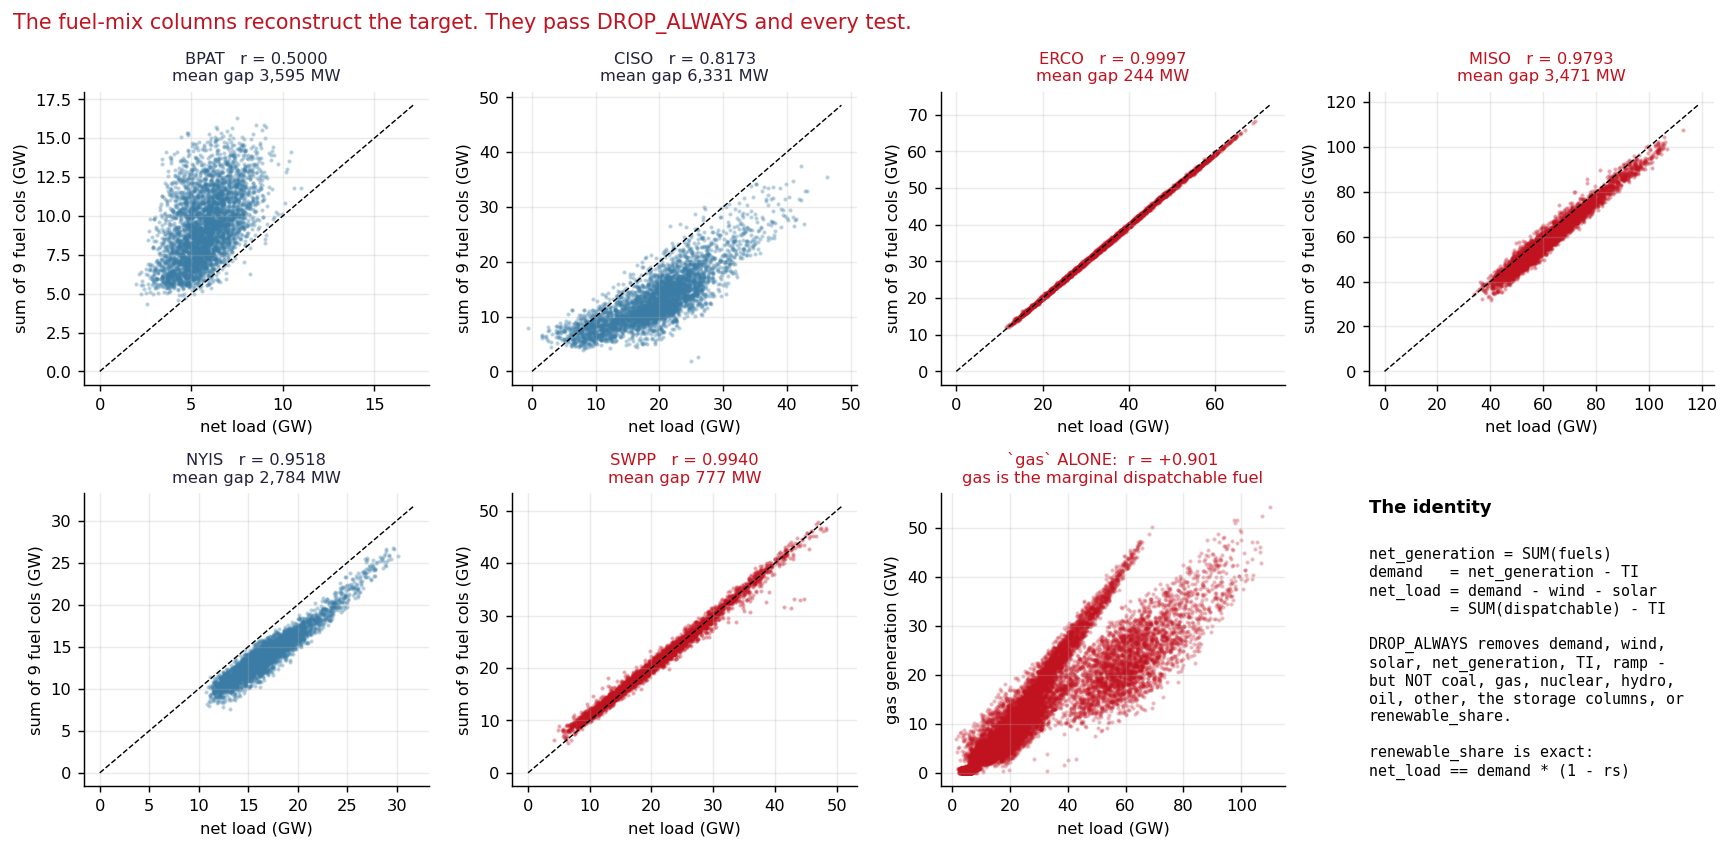

reconstruction WITH total_interchange added back:
  corr = 0.997478   mean |gap| 1,165 MW   median 220 MW
  against a mean |net_load| of 26,531 MW

per zone, fuel sum alone (total_interchange IS dropped by DROP_ALWAYS):
  ERCO:  r = 0.99966   mean gap      244 MW
  SWPP:  r = 0.99400   mean gap      777 MW
  MISO:  r = 0.97927   mean gap    3,471 MW
  NYIS:  r = 0.95185   mean gap    2,784 MW
  CISO:  r = 0.81730   mean gap    6,331 MW
  BPAT:  r = 0.50002   mean gap    3,595 MW

renewable_share identity  net_load == demand * (1 - rs):
  max |residual| over all 315,485 rows = 0.000000 MW

candidates that are same-hour realised quantities and still admissible:
   []


In [17]:
d = panel.copy()
d["fuel_sum"] = d[FUELS].fillna(0).sum(axis=1)

fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.6))
stats = {}
for ax, (z, g) in zip(axes.flat, d.groupby(cfg.GROUP_COL)):
    r = float(np.corrcoef(g["fuel_sum"], g[cfg.TARGET])[0, 1])
    gap = float((g["fuel_sum"] - g[cfg.TARGET]).abs().mean())
    stats[z] = (r, gap)
    s = g.sample(min(4000, len(g)), random_state=cfg.SEED)
    ax.scatter(s[cfg.TARGET] / 1000, s["fuel_sum"] / 1000, s=2, alpha=.25,
               color=BAD if r > .97 else ACC)
    lim = [0, max(s[cfg.TARGET].max(), s["fuel_sum"].max()) / 1000 * 1.05]
    ax.plot(lim, lim, "k--", lw=.8)
    ax.set_title(f"{z}   r = {r:.4f}\nmean gap {gap:,.0f} MW", fontsize=9,
                 color=BAD if r > .97 else INK)
    ax.set_xlabel("net load (GW)"); ax.set_ylabel("sum of 9 fuel cols (GW)")

ax = axes.flat[6]
s = d.sample(20000, random_state=cfg.SEED)
r_gas = float(d[["gas", cfg.TARGET]].corr().iloc[0, 1])
ax.scatter(s[cfg.TARGET] / 1000, s["gas"] / 1000, s=2, alpha=.2, color=BAD)
ax.set_title(f"`gas` ALONE:  r = {r_gas:+.3f}\ngas is the marginal dispatchable fuel",
             fontsize=9, color=BAD)
ax.set_xlabel("net load (GW)"); ax.set_ylabel("gas generation (GW)")

ax = axes.flat[7]; ax.set_axis_off()
ax.text(0, .98, "The identity", fontweight="bold", fontsize=10, va="top")
ax.text(0, .82,
        "net_generation = SUM(fuels)\n"
        "demand   = net_generation - TI\n"
        "net_load = demand - wind - solar\n"
        "         = SUM(dispatchable) - TI\n\n"
        "DROP_ALWAYS removes demand, wind,\n"
        "solar, net_generation, TI, ramp -\n"
        "but NOT coal, gas, nuclear, hydro,\n"
        "oil, other, the storage columns, or\n"
        "renewable_share.\n\n"
        "renewable_share is exact:\n"
        "net_load == demand * (1 - rs)",
        fontsize=8.3, va="top", family="monospace")
fig.suptitle("The fuel-mix columns reconstruct the target. They pass DROP_ALWAYS and every test.",
             fontsize=11.5, x=.01, ha="left", color=BAD)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_leakage_fuel_columns.png"); plt.show()

# The identity, measured rather than asserted.
recon = d["fuel_sum"] - d["total_interchange"].fillna(0)
err = (recon - d[cfg.TARGET]).abs()
rs_resid = (d["demand"] * (1 - d["renewable_share"]) - d[cfg.TARGET]).abs()

print("reconstruction WITH total_interchange added back:")
print(f"  corr = {np.corrcoef(recon, d[cfg.TARGET])[0,1]:.6f}   "
      f"mean |gap| {err.mean():,.0f} MW   median {err.median():,.0f} MW")
print(f"  against a mean |net_load| of {d[cfg.TARGET].abs().mean():,.0f} MW")
print("\nper zone, fuel sum alone (total_interchange IS dropped by DROP_ALWAYS):")
for z, (r, gap) in sorted(stats.items(), key=lambda kv: -kv[1][0]):
    print(f"  {z}:  r = {r:.5f}   mean gap {gap:>8,.0f} MW")
print(f"\nrenewable_share identity  net_load == demand * (1 - rs):")
print(f"  max |residual| over all {len(d):,} rows = {rs_resid.max():.6f} MW")
print("\ncandidates that are same-hour realised quantities and still admissible:")
print("  ", [c for c in CANDS if c in LEAKY])

**What I see:** ERCO's fuel sum reconstructs net load at r = 0.9997 with a mean gap of 244 MW (mean net load 33.9 GW). SWPP reaches r = 0.9940, MISO 0.9793, NYIS 0.952. Adding `total_interchange` back gives pooled r = 0.9975 with a median gap of 220 MW. `net_load = demand × (1 − renewable_share)` holds with a maximum residual of 0.000000 MW over all 315,485 rows. Only BPAT (r = 0.50) and CISO (r = 0.82) escape, because of their large net interchange.

**What it means:** These columns cannot be features, for two reasons. They sum to the target, so a model using them is doing arithmetic. And they are same-hour realised generation, unknown at a 24-hour forecast origin.

**What I do:** Exclude the nine fuel columns and `renewable_share` via `cfg.REALISED_GENERATION_COLS`, enforced by `tests/test_leakage.py`. Lagged fuels such as `wind_lag24` are known at the origin and stay, via `exog_lags`.


### 2.16 — What the audit changes

| # | Step | Status here | Action |
|---|---|---|---|
| 1 | Numerical imputation | ≤3 h interpolation + `SimpleImputer(median)` | could test `add_indicator=True` |
| 1 | Categorical imputation | not applicable — `zone` is never missing | none |
| 2 | One-hot | `OneHotZone` | shipped default |
| 2 | Ordinal | `OrdinalZone` | kept as a comparison |
| 2 | Target encoding | `SmoothedTargetEncoder` | kept; `smoothing` not tuned |
| 3 | Standardisation | absent from the shared pipeline | notebook 04 scales inside its Ridge pipeline |
| 3 | Log transform | inadmissible — target crosses zero | `asinh` if ever needed |
| 4 | Datetime splitting | `CalendarFeatures`, 12 columns (11 reach the model), cyclical | keep |
| 4 | Interactions | `renewable_share` removed (2.15); only its lag remains | could add `temp × hour` |
| 4 | Binning | absent | not needed for trees |
| 5 | Selection | `MutualInfoSelector`, per fold | fix the docstring; rank per zone |

**Why the weather columns are allowed.** The fuel columns are excluded because they are terms of the identity `net_load = demand − wind − solar`. Weather columns (irradiance, hub-height wind, temperature) cause those terms but are not part of them, and a weather forecast exists at the forecast origin. All fifteen weather columns pass both tests. Caveat: the panel uses ERA5 reanalysis (weather as it happened), which is optimistic beyond h=1; notebook 06 re-scores the holdout on archived forecasts.


---

## 2.17 — Additional feature families

### 2.17a — Per-zone normalised variants

Each target-derived column is divided by that zone's trailing 168-hour mean. The zones differ by an order of magnitude (`net_load_lag1` ~6,000 MW in BPAT, ~64,000 MW in MISO), so a scale-free version lets the tree learn shape without first separating zones. I chose this over a fitted per-zone z-score because it learns nothing (`PerZoneRelative.fit` is a no-op, checked by `test_per_zone_relative_learns_nothing`) and it moves with the zone as load grows. Panel (b) shows the per-fold change.


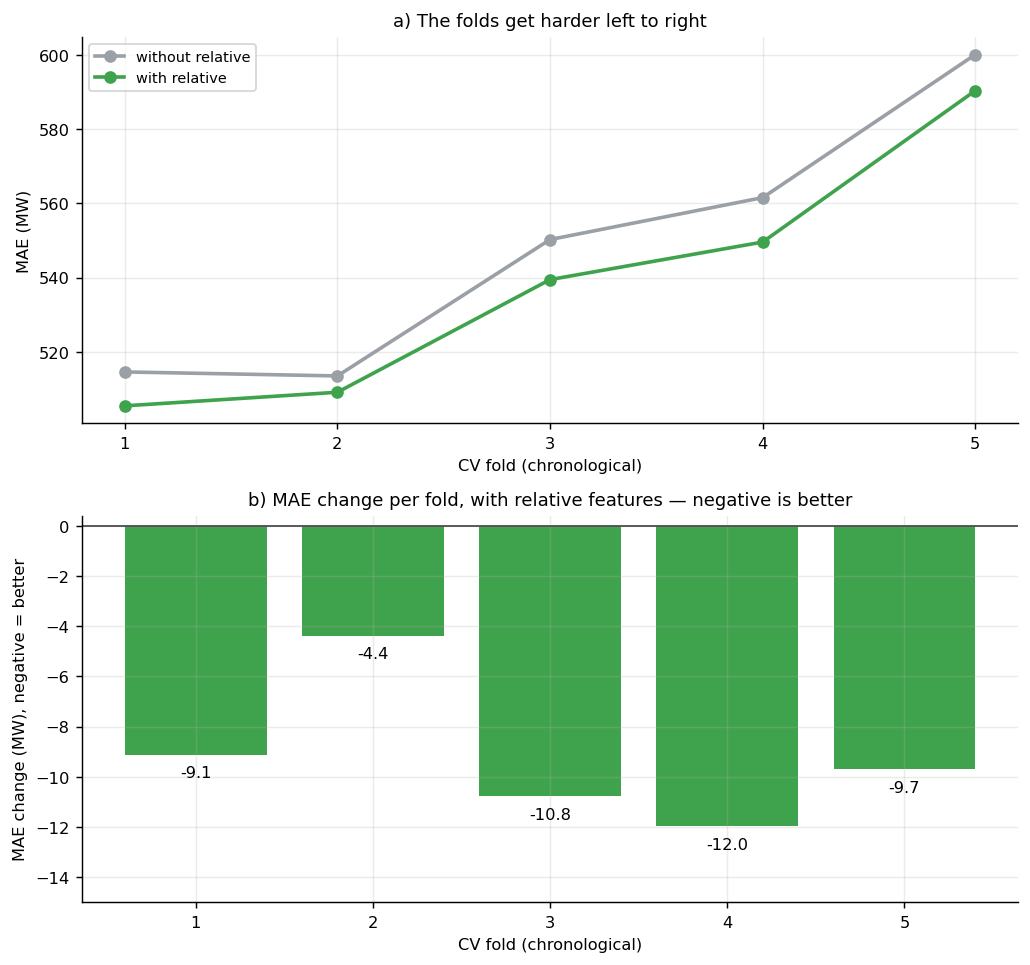

created 9 relative features; feature count 60 -> 69
    net_load_lag1_rel
    net_load_lag2_rel
    net_load_lag3_rel
    net_load_lag24_rel
    net_load_lag168_rel
    net_load_roll24_mean_rel
    net_load_roll24_std_rel
    net_load_roll168_std_rel
    net_load_ramp_1_24_rel

MAE 547.98 -> 538.78 (-9.19 MW); fold sd 32.25 -> 30.86
improved in 5/5 folds; fold-1 delta -9.13, last-fold delta -9.70


In [18]:
# WHAT: does the per-zone relative family earn its place?
# WHY:  the plan requires the family; that is not the same as it helping. Measure.
# NOTE: paired by fold -- same splits, same rows, one step toggled.
# 2.11 rebound `y` to the DEV block. These sections score the whole of `df` (the dev block),
# so the target is named explicitly rather than inherited -- the same
# self-contained convention the audit cells use.
y_full = df[cfg.TARGET]

rel_scores = {}
for flag, label in [(False, "without"), (True, "with")]:
    pr = P.make_supervised_pipeline(lags=lags, per_zone_relative=flag)
    rel_scores[label] = -cross_val_score(pr, df, y_full, cv=cv, scoring="neg_mean_absolute_error")
rel_delta = rel_scores["with"] - rel_scores["without"]

pr = P.make_supervised_pipeline(lags=lags, per_zone_relative=True).fit(df, y_full)
rel_names = [c for c in pr.named_steps["select"].selected_ if c.endswith("_rel")]
n_all = len(pr.named_steps["select"].selected_)

fig, axes = plt.subplots(2, 1, figsize=(8.0, 7.5))
ax = axes[0]
f = np.arange(1, len(rel_delta) + 1)
ax.plot(f, rel_scores["without"], "o-", lw=2, color="#9aa0a6", label="without relative")
ax.plot(f, rel_scores["with"], "o-", lw=2, color="#3fa34d", label="with relative")
ax.set_xticks(f); ax.set_xlabel("CV fold (chronological)"); ax.set_ylabel("MAE (MW)")
ax.set_title("a) The folds get harder left to right", fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.25)

ax = axes[1]
ax.bar(f, rel_delta, color=["#c1121f" if d > 0 else "#3fa34d" for d in rel_delta])
ax.axhline(0, color="0.3", lw=1)
for i, d in enumerate(rel_delta, 1):
    ax.text(i, d + (0.4 if d > 0 else -0.9), f"{d:+.1f}", ha="center", fontsize=9)
# Room below the most negative bar, or its value label lands on the tick label.
ax.set_ylim(min(rel_delta.min(), 0) * 1.22 - 0.4, max(rel_delta.max(), 0) * 1.22 + 0.4)
ax.set_xticks(f); ax.set_xlabel("CV fold (chronological)")
ax.set_ylabel("MAE change (MW), negative = better")
ax.set_title("b) MAE change per fold, with relative features — negative is better",
             fontsize=10)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_per_zone_relative.png", bbox_inches="tight")
plt.show()

print(f"created {len(rel_names)} relative features; feature count {n_all - len(rel_names)} -> {n_all}")
for c in rel_names:
    print("   ", c)
print(f"\nMAE {rel_scores['without'].mean():.2f} -> {rel_scores['with'].mean():.2f} "
      f"({rel_delta.mean():+.2f} MW); fold sd {rel_scores['without'].std():.2f} -> "
      f"{rel_scores['with'].std():.2f}")
print(f"improved in {(rel_delta < 0).sum()}/{len(rel_delta)} folds; "
      f"fold-1 delta {rel_delta[0]:+.2f}, last-fold delta {rel_delta[-1]:+.2f}")

**What I see:** Nine features are added, taking the matrix from 60 to 69. Mean MAE improves **547.98 → 538.78** (**9.19 MW**) and the fold SD narrows from 32.25 to 30.86. The family helps in **all five folds** (fold 1 −9.13, last fold −9.70).

**What it means:** The family helps in every fold, by about 9 MW on average. Five folds are too few to read a trend across them.

**What I do:** Keep it, on by default.


### 2.18 — Is the MI ranking stable across folds?

MI is computed separately inside each fold's training window. Per-fold refitting is the leakage guard; this asks whether it also gives a stable ranking. Panel (a): one line per fold; panel (b): each feature's rank across folds.


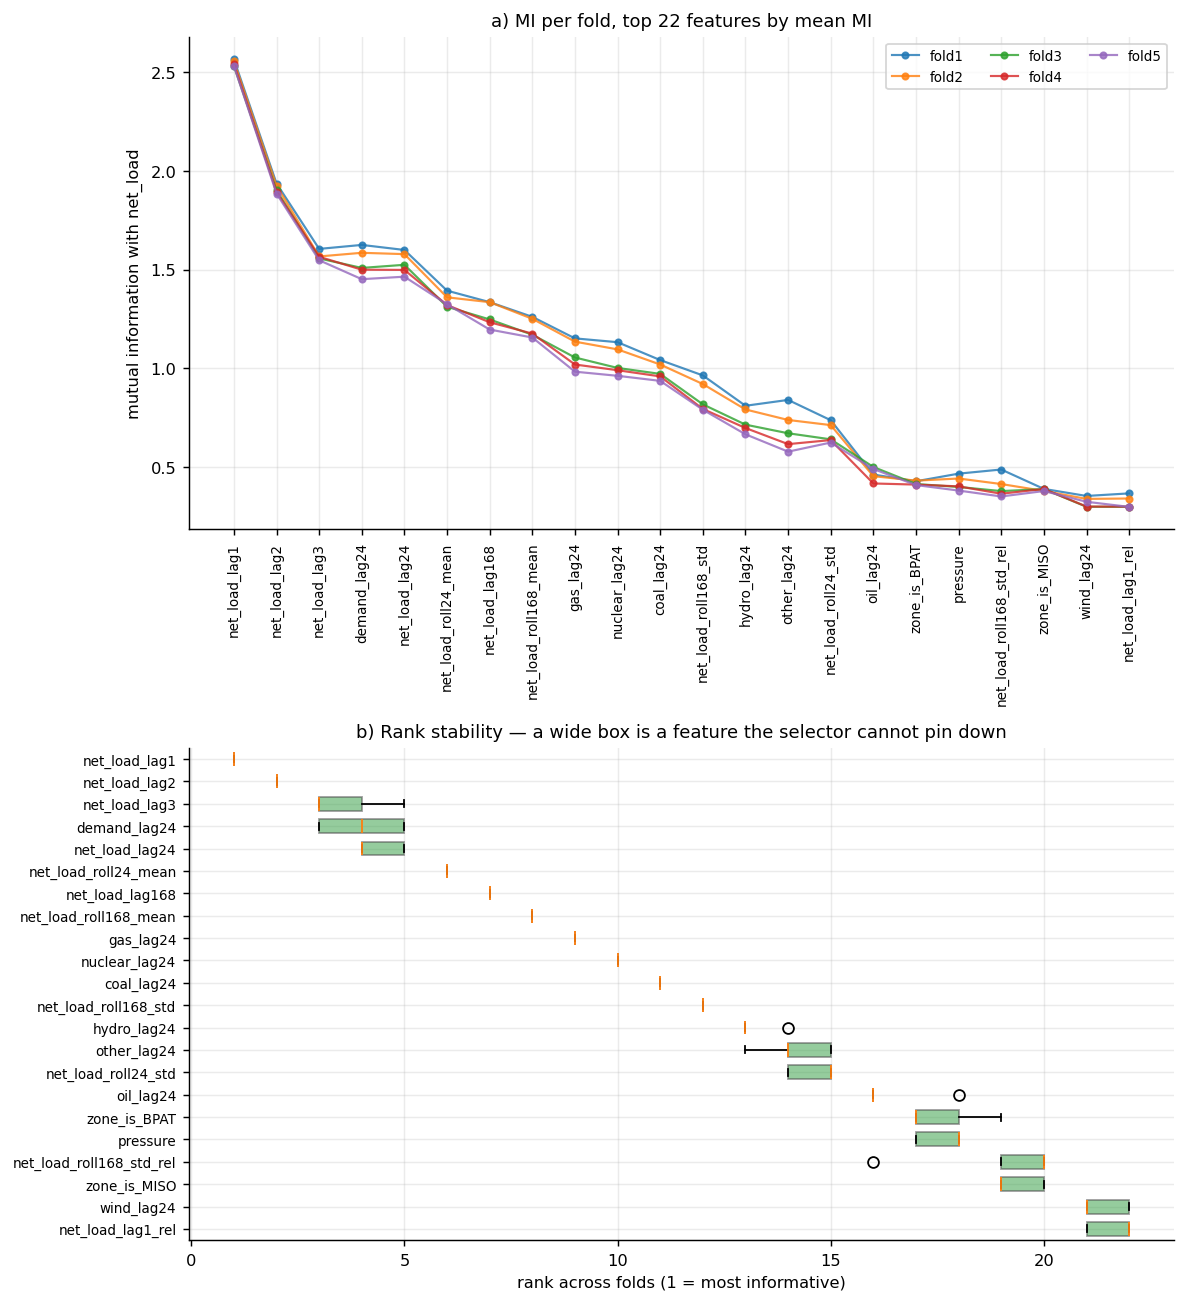

top 10 by mean MI:
  net_load_lag1                MI 2.546  rank 1-1
  net_load_lag2                MI 1.908  rank 2-2
  net_load_lag3                MI 1.568  rank 3-5
  demand_lag24                 MI 1.534  rank 3-5
  net_load_lag24               MI 1.533  rank 4-5
  net_load_roll24_mean         MI 1.341  rank 6-6
  net_load_lag168              MI 1.269  rank 7-7
  net_load_roll168_mean        MI 1.202  rank 8-8
  gas_lag24                    MI 1.068  rank 9-9
  nuclear_lag24                MI 1.035  rank 10-10

features whose rank never moves: 10 of 69
least stable:
  doy_cos                      rank spread 15 (ranks 32-47)
  doy_sin                      rank spread 14 (ranks 34-48)
  wind_speed                   rank spread 11 (ranks 46-57)
  dayofyear                    rank spread 10 (ranks 27-37)
  humidity                     rank spread 8 (ranks 50-58)


In [19]:
# WHAT: MI per feature, recomputed inside each fold's TRAINING window only.
# WHY:  the selector is refit per fold. This asks whether that refit lands in the
#       same place each time -- honesty and stability are different properties.
# NOTE: MI is a k-NN estimator, O(n log n) per feature with a large constant, so it
#       runs on a subsample. The RANKING stabilises long before the estimate does.
MI_SAMPLE = 12_000
pipe_full = P.make_supervised_pipeline(lags=lags, encoding="onehot").fit(df, y_full)
feat_names = list(pipe_full.named_steps["select"].selected_)

mi_folds = {}
for k, (tr_i, _) in enumerate(cv.split(df), 1):
    sub = df.iloc[tr_i]
    pk = P.make_supervised_pipeline(lags=lags, encoding="onehot").fit(sub, sub[cfg.TARGET])
    Xk = pd.DataFrame(pk[:-1].transform(sub), columns=pk.named_steps["select"].selected_)
    yk = sub[cfg.TARGET].to_numpy()
    m = Xk.notna().all(axis=1).to_numpy()
    Xk, yk = Xk[m], yk[m]
    if len(Xk) > MI_SAMPLE:
        idx = np.random.RandomState(cfg.SEED).choice(len(Xk), MI_SAMPLE, replace=False)
        Xk, yk = Xk.iloc[idx], yk[idx]
    mi_folds[f"fold{k}"] = pd.Series(
        mutual_info_regression(Xk, yk, random_state=cfg.SEED), index=Xk.columns)

mi_df = pd.DataFrame(mi_folds)
mi_mean = mi_df.mean(axis=1).sort_values(ascending=False)
mi_df = mi_df.loc[mi_mean.index]
mi_rank = mi_df.rank(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(9.2, 10.1))
ax = axes[0]
top = mi_mean.index[:22]
for c in mi_df.columns:
    ax.plot(range(len(top)), mi_df.loc[top, c], "o-", ms=3.5, lw=1.2, alpha=0.8, label=c)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top, rotation=90, fontsize=7.5)
ax.set_ylabel("mutual information with net_load")
ax.set_title("a) MI per fold, top 22 features by mean MI", fontsize=10)
ax.legend(fontsize=7.5, ncol=3); ax.grid(alpha=0.25)

ax = axes[1]
bp = ax.boxplot([mi_rank.loc[c] for c in top], vert=False, patch_artist=True,
                widths=0.62, showfliers=True)
for p_ in bp["boxes"]:
    p_.set_facecolor("#3fa34d"); p_.set_alpha(0.55); p_.set_edgecolor("0.3")
ax.set_yticklabels(top, fontsize=7.5); ax.invert_yaxis()
ax.set_xlabel("rank across folds (1 = most informative)")
ax.set_title("b) Rank stability — a wide box is a feature the selector cannot pin down",
             fontsize=10)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_mi_stability.png", bbox_inches="tight")
plt.show()

spread = (mi_rank.max(axis=1) - mi_rank.min(axis=1)).sort_values(ascending=False)
print("top 10 by mean MI:")
for c in mi_mean.index[:10]:
    print(f"  {c:28s} MI {mi_mean[c]:.3f}  rank {mi_rank.loc[c].min():.0f}-{mi_rank.loc[c].max():.0f}")
print(f"\nfeatures whose rank never moves: {(spread == 0).sum()} of {len(spread)}")
print("least stable:")
for c in spread.index[:5]:
    print(f"  {c:28s} rank spread {spread[c]:.0f} (ranks {mi_rank.loc[c].min():.0f}-{mi_rank.loc[c].max():.0f})")

**What I see:** The top barely moves. `net_load_lag1` (mean MI 2.546) is first in every fold and `net_load_lag2` (1.908) second; `net_load_lag3`, `demand_lag24` and `net_load_lag24` swap among ranks 3–5, and ranks 6–10 are fixed. The first feature that is not a lag or rolling statistic is `zone_is_BPAT`, at rank 17. Only 10 of 69 features never move; the instability is in the tail, worst for `doy_cos` and `doy_sin` (rank spreads 15 and 14).

**What it means:** Per-fold refitting is cheap here because the top of the ranking is stable. The unstable features are mostly annual-cycle terms, which is expected since each fold covers a different part of the year.

**What I do:** Keep refitting per fold. A stable ranking is not a reason to compute it once on the whole development block.


### 2.19 — VIF: collinearity

VIF_i = 1 / (1 − R²_i); above 10 is the usual alarm. It is computed from the inverse correlation matrix. Collinearity inflates coefficient variance, and the shipped tree model has no coefficients, so a high VIF is not a reason to drop a feature. It matters for the Ridge rung in notebook 04 and for SHAP in notebook 07, where collinear features split the credit.


exact linear dependences (VIF = infinity): ['cdd', 'dhi', 'dni_horiz', 'ghi', 'hdd', 'temp', 'zone_is_BPAT', 'zone_is_CISO', 'zone_is_ERCO', 'zone_is_MISO', 'zone_is_NYIS', 'zone_is_SWPP']


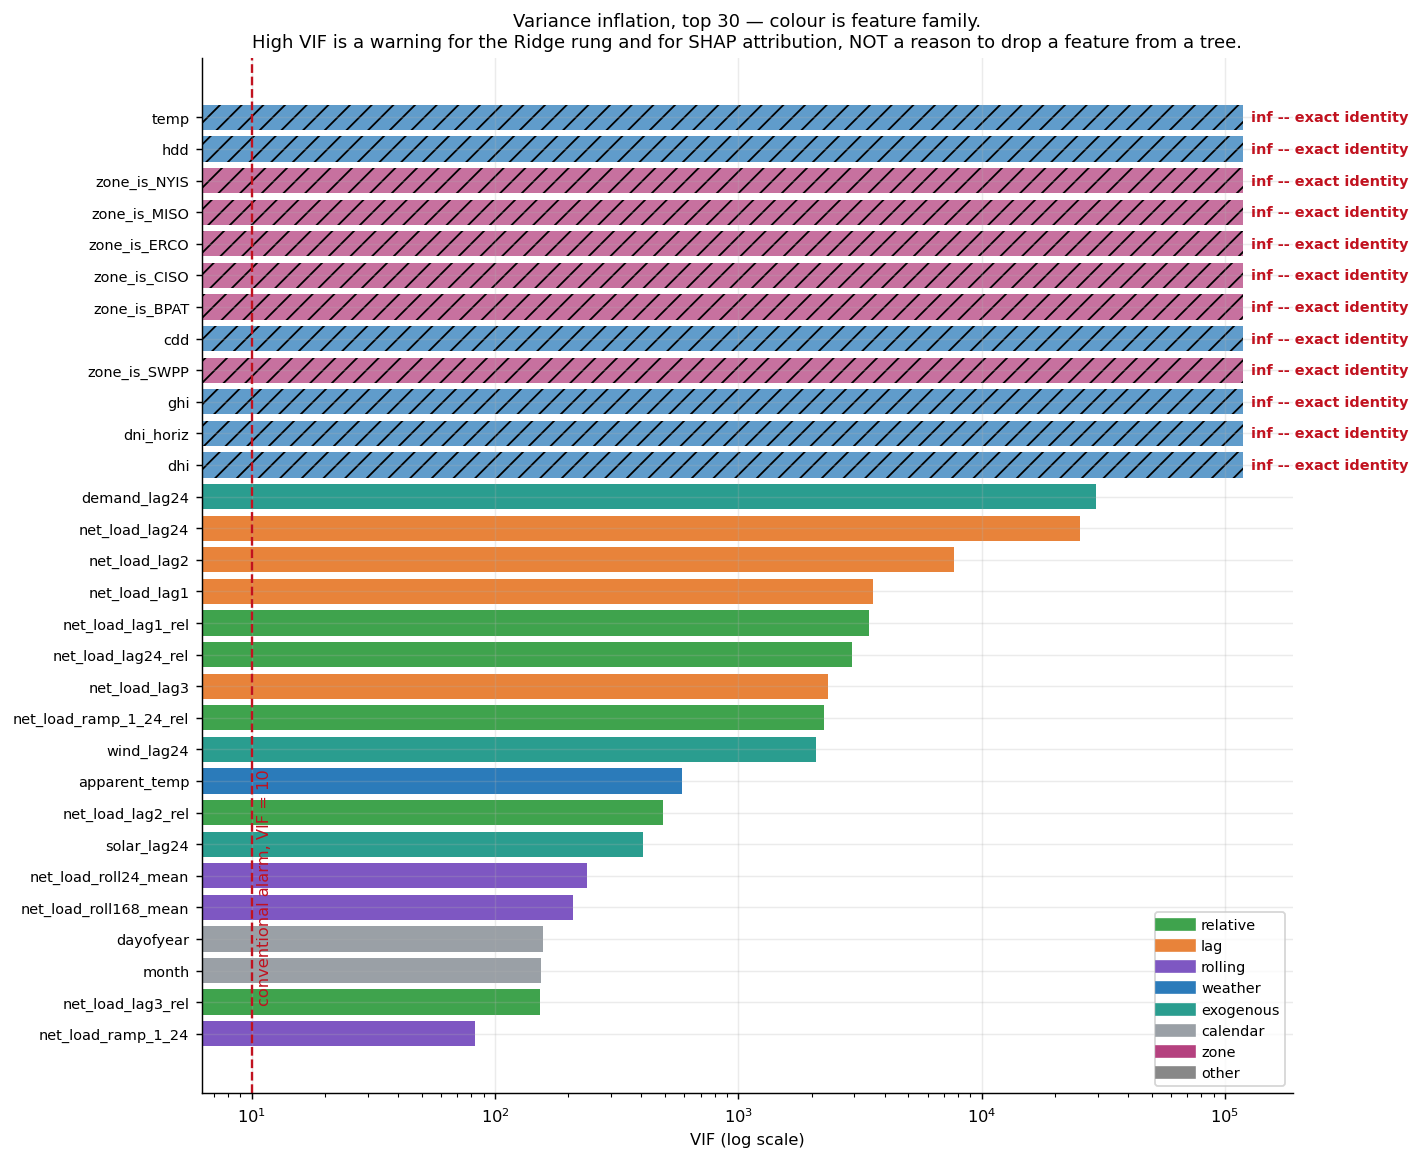

features with VIF > 10 : 45 of 69
features with VIF > 100: 29

worst ten:
  temp                                    inf   [weather]
  hdd                                     inf   [weather]
  zone_is_NYIS                            inf   [zone]
  zone_is_MISO                            inf   [zone]
  zone_is_ERCO                            inf   [zone]
  zone_is_CISO                            inf   [zone]
  zone_is_BPAT                            inf   [zone]
  cdd                                     inf   [weather]
  zone_is_SWPP                            inf   [zone]
  ghi                                     inf   [weather]

by family (median VIF):
           count  median      max
family                           
calendar      11     4.4    157.0
exogenous     10    33.0  29632.3
lag            5  3591.7  25330.6
relative       9   153.0   3430.1
rolling        5    82.6    239.1
weather       23    12.5      inf
zone           6     inf      inf


In [20]:
# WHAT: VIF for every feature in the final matrix.
# WHY:  required by the plan, and the relative family makes it live -- a ratio and
#       its numerator share information by construction.
# NOTE: VIF_i = diag(inv(corr(X)))_i. Identical to regressing each feature on the
#       rest, at the cost of ONE inversion rather than 69 least-squares fits.
#       A pseudo-inverse never raises on a singular block -- but it does NOT
#       report a huge VIF for one, it TRUNCATES the null space and reports a
#       SMALL one. The first version of this cell claimed the opposite in this
#       very comment, and shipped ghi at VIF 2.2 while ghi = dhi + dni_horiz
#       holds to machine zero in every row: the exactly-dependent block was
#       ranked as the LEAST collinear in the matrix. The eigendecomposition
#       below finds the exact dependences first; their VIF is infinity, stated
#       as such rather than as whatever the truncation leaves behind.
VIF_SAMPLE = 40_000
Xf = pd.DataFrame(pipe_full[:-1].transform(df), columns=feat_names)
Xv = Xf.dropna()
if len(Xv) > VIF_SAMPLE:
    Xv = Xv.sample(VIF_SAMPLE, random_state=cfg.SEED)
keep = [c for c in Xv.columns if Xv[c].std() > 0]
C = np.corrcoef(Xv[keep].to_numpy(), rowvar=False)
# .copy() because np.diag returns a READ-ONLY view -- assigning the infinities
# into a Series wrapping it raised 'assignment destination is read-only' and
# killed the 2026-08-29 11:02 run six minutes in.
vif = pd.Series(np.diag(np.linalg.pinv(C)).copy(), index=keep)
# An eigenvalue at numerical zero IS an exact linear dependence, and every
# feature with weight in its eigenvector belongs to it. Their true VIF is
# infinite; the near-zero eigenvalue that float noise leaves for the lag
# identity (net_load_lag24 = demand_lag24 - wind_lag24 - solar_lag24) stays
# above this cutoff and keeps its finite-but-huge value, which is the honest
# reading of a 40,000-row sampled correlation.
evals, evecs = np.linalg.eigh(C)
exact_members = sorted({keep[j]
                        for i in np.where(evals < 1e-10 * evals.max())[0]
                        for j in np.where(np.abs(evecs[:, i]) > 1e-6)[0]})
vif[exact_members] = np.inf
vif = vif.sort_values(ascending=False)
print(f"exact linear dependences (VIF = infinity): {exact_members}")

# THE FAMILY MAP IS ASKED FOR, NOT RESTATED. This cell used to carry its own
# lambda -- `"weather" if c in cfg.WEATHER_FEATURES or c.startswith("temp_lag")` --
# which was correct only while `temp` was the sole lagged weather column and the
# weather set had four members. With fifteen columns and four lagged ones,
# `cloud_cover_lag24`, `ghi_lag24` and every derived column fell through to
# "calendar" and the figure would have mislabelled them in colour while saying
# nothing was wrong. `P.feature_family` is the single definition; the only thing
# kept local is the split of `_rel` out of its base family, which is a property of
# THIS figure rather than of the taxonomy.
def fam(c):
    return "relative" if c.endswith("_rel") else P.feature_family(c)


FAMC = {"relative": "#3fa34d", "lag": "#e8833a", "rolling": "#7e57c2",
        "weather": "#2b7bba", "exogenous": "#2a9d8f", "calendar": "#9aa0a6",
        "zone": "#b5417f", "other": "#888"}
_missing = {fam(c) for c in vif.index} - set(FAMC)
assert not _missing, (f"no colour for family {sorted(_missing)} -- see "
                      f"src/features.py feature_family() and add it here.")

fig, ax = plt.subplots(figsize=(11, 9))
sh = vif.head(30)[::-1]
# An infinite bar cannot be drawn on a log axis; it is drawn at 4x the largest
# finite VIF, hatched, and labelled as an exact identity so the stand-in cannot
# be read as a measurement.
_finite_max = float(vif[np.isfinite(vif)].max())
_stand_in = _finite_max * 4
_drawn = sh.replace(np.inf, _stand_in)
bars = ax.barh(range(len(sh)), _drawn.values,
               color=[FAMC[fam(c)] for c in sh.index])
for _y, (_name, _val) in enumerate(sh.items()):
    if np.isinf(_val):
        bars[_y].set_hatch("//")
        bars[_y].set_alpha(0.75)
        ax.text(_stand_in * 1.08, _y, "inf -- exact identity", va="center",
                fontsize=8, color="#c1121f", fontweight="bold")
ax.set_yticks(range(len(sh))); ax.set_yticklabels(sh.index, fontsize=8)
ax.axvline(10, color="#c1121f", ls="--", lw=1.3)
ax.text(10.5, 1.0, "conventional alarm, VIF = 10", color="#c1121f", fontsize=9, rotation=90)
ax.set_xscale("log"); ax.set_xlabel("VIF (log scale)")
ax.set_title("Variance inflation, top 30 — colour is feature family.\n"
             "High VIF is a warning for the Ridge rung and for SHAP attribution, "
             "NOT a reason to drop a feature from a tree.", fontsize=10)
handles = [plt.Line2D([], [], color=v, lw=7, label=k) for k, v in FAMC.items()]
ax.legend(handles=handles, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_vif.png", bbox_inches="tight")
plt.show()

print(f"features with VIF > 10 : {(vif > 10).sum()} of {len(vif)}")
print(f"features with VIF > 100: {(vif > 100).sum()}")
print("\nworst ten:")
for c in vif.index[:10]:
    print(f"  {c:30s} {vif[c]:12,.1f}   [{fam(c)}]")
print("\nby family (median VIF):")
vf = pd.DataFrame({"vif": vif, "family": [fam(c) for c in vif.index]})
print(vf.groupby("family")["vif"].agg(["count", "median", "max"]).round(1).to_string())

**What I see:** Twelve features have infinite VIF because of exact identities: `ghi = dhi + dni_horiz`, `cdd − hdd = temp − 15`, and the six zone dummies summing to one. In total **45 of 69** features exceed VIF 10 and **29 exceed 100**. Median VIF by family: lag **3,592**, relative **153**, rolling **83**, exogenous **33**, weather **12.5**, calendar **4.4**, zone infinite.

**What it means:** Collinearity is severe, including in the weather block. The tree is unaffected, which is why §2.17 still found an improvement from these features. Ridge coefficients and SHAP rankings must be read with care.

**What I do:** Drop nothing on VIF alone. Notebook 04 does not present linear coefficients as importances, and notebook 07 groups `lag_k` with `lag_k_rel` before reading a ranking.


### 2.20 — The forward-selection curve: how many features are needed?

Score the pipeline with `MutualInfoSelector(k)` for a sweep of k, on the last CV fold only. This is a filter-ordered curve (fixed MI order, 11 fits), not a greedy wrapper, so it cannot prove no smaller set exists.


  k=  1  MAE  1220.03


  k=  2  MAE   746.24


  k=  3  MAE   771.89


  k=  5  MAE   755.43


  k=  8  MAE   728.57


...

  k= 16  MAE   714.34


  k= 20  MAE   714.95


  k= 25  MAE   701.70


  k= 30  MAE   652.28


  k= 69  MAE   590.33


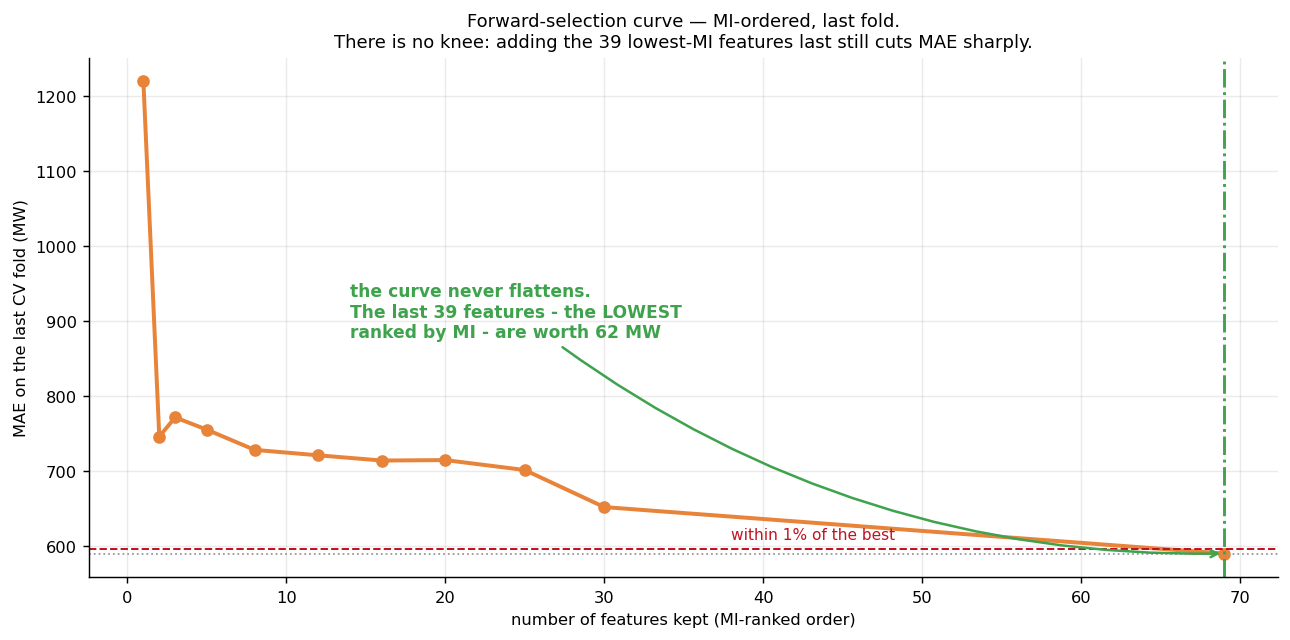


best k=69 (MAE 590.33); all 69 features -> 590.33
knee (first k within 1% of best): 69 features, MAE 590.33
cost of dropping to the knee: +0.00 MW

k=30 -> k=69 improves MAE by 61.95 MW - the selector's 39 lowest-MI features

the selected feature set, in MI order:
    net_load_lag1
    net_load_lag2
    net_load_lag3
    demand_lag24
    net_load_lag24
    net_load_roll24_mean
    net_load_lag168
    net_load_roll168_mean
    gas_lag24
    nuclear_lag24
    coal_lag24
    net_load_roll168_std
    hydro_lag24
    other_lag24
    net_load_roll24_std
    oil_lag24
    zone_is_BPAT
    pressure
    net_load_roll168_std_rel
    zone_is_MISO
    wind_lag24
    net_load_lag1_rel
    apparent_temp
    temp
    solar_lag24
    renewable_share_lag24
    temp_lag24
    net_load_lag2_rel
    dew_point
    net_load_ramp_1_24
    net_load_roll24_std_rel
    dayofyear
    net_load_lag3_rel
    zone_is_NYIS
    hdd
    net_load_lag24_rel
    zone_is_ERCO
    cdd
    doy_cos
    month
    net_load_lag

In [21]:
# WHAT: validation MAE against number of features, in MI-ranked order.
# WHY:  k='all' is a decision. This is the evidence for or against it.
# NOTE: last CV fold only (11 fits, not 55), and MI-ORDERED rather than greedy --
#       see the markdown above for what that trade-off costs.
from sklearn.metrics import mean_absolute_error
tr_i, te_i = list(cv.split(df))[-1]
tr_df, te_df = df.iloc[tr_i], df.iloc[te_i]
order = list(mi_mean.index)
KS = [1, 2, 3, 5, 8, 12, 16, 20, 25, 30, len(order)]
fwd = {}
for k in KS:
    pk = P.make_supervised_pipeline(lags=lags, encoding="onehot", k=k)
    pk.fit(tr_df, tr_df[cfg.TARGET])
    fwd[k] = float(mean_absolute_error(te_df[cfg.TARGET], pk.predict(te_df)))
    print(f"  k={k:3d}  MAE {fwd[k]:8.2f}")

fs = pd.Series(fwd)
best_k = int(fs.idxmin())
within1 = fs[fs <= fs.min() * 1.01]
knee = int(within1.index.min())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(fs.index, fs.values, "o-", lw=2.2, ms=6, color="#e8833a")
ax.axhline(fs.min(), color="0.6", ls=":", lw=1)
ax.axhline(fs.min() * 1.01, color="#c1121f", ls="--", lw=1.1)
ax.annotate("within 1% of the best", (fs.index.max() * 0.55, fs.min() * 1.01),
            xytext=(0, 4), textcoords="offset points", va="bottom", fontsize=8.5,
            color="#c1121f")
ax.axvline(knee, color="#3fa34d", lw=1.6, ls="-.")
drop_tail = fs[30] - fs.iloc[-1]
ax.annotate(f"the curve never flattens.\nThe last 39 features - the LOWEST\n"
            f"ranked by MI - are worth {drop_tail:.0f} MW",
            xy=(knee, fs[knee]), xytext=(14, fs.max() * 0.72), fontsize=9.5,
            color="#3fa34d", fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#3fa34d", lw=1.4,
                            connectionstyle="arc3,rad=0.18"))
ax.set_xlabel("number of features kept (MI-ranked order)")
ax.set_ylabel("MAE on the last CV fold (MW)")
ax.set_title("Forward-selection curve — MI-ordered, last fold.\n"
             "There is no knee: adding the 39 lowest-MI features "
             "last still cuts MAE sharply.", fontsize=10)
ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_forward_selection.png", bbox_inches="tight")
plt.show()

print(f"\nbest k={best_k} (MAE {fs.min():.2f}); all {len(order)} features -> {fs.iloc[-1]:.2f}")
print(f"knee (first k within 1% of best): {knee} features, MAE {fs[knee]:.2f}")
print(f"cost of dropping to the knee: {fs[knee] - fs.min():+.2f} MW")
print(f"\nk=30 -> k={len(order)} improves MAE by {fs[30]-fs.iloc[-1]:.2f} MW "
      f"- the selector's 39 lowest-MI features")
print("\nthe selected feature set, in MI order:")
for c in order[:knee]:
    print("   ", c)

**What I see:** MAE falls from **1,220 MW** at k=1 to **746** at k=2, is worse at k=3 (771.89), reaches **652.28** at k=30 and **590.33** with all 69. The 39 features MI ranks lowest are jointly worth **61.95 MW**. There is no knee: the best score uses all 69 features.

**What it means:** MI is the wrong criterion for dropping features. The last block includes `hour_sin`, `hour_cos`, `dayofweek`, `dow_sin`, `is_weekend`, `humidity`, `wind_speed` and `cloud_cover`. MI scores features one at a time on the pooled panel, while the model uses them conditionally: given the lag, the hour says where on the daily curve it is.

**What I do:** Keep `MutualInfoSelector(k='all')`. Its job is the leakage guard and dropping all-NaN columns, not reducing dimensions.


### 2.21 — SHAP as a selection check

MI ranks features before any model is fitted; SHAP measures what the fitted model uses. If they disagree, the selector chooses on a criterion the model does not share. SHAP is not causal, is computed on the development block (not the holdout), and splits credit between collinear features (§2.19). Panel (b): points on the diagonal mean MI and SHAP agree.


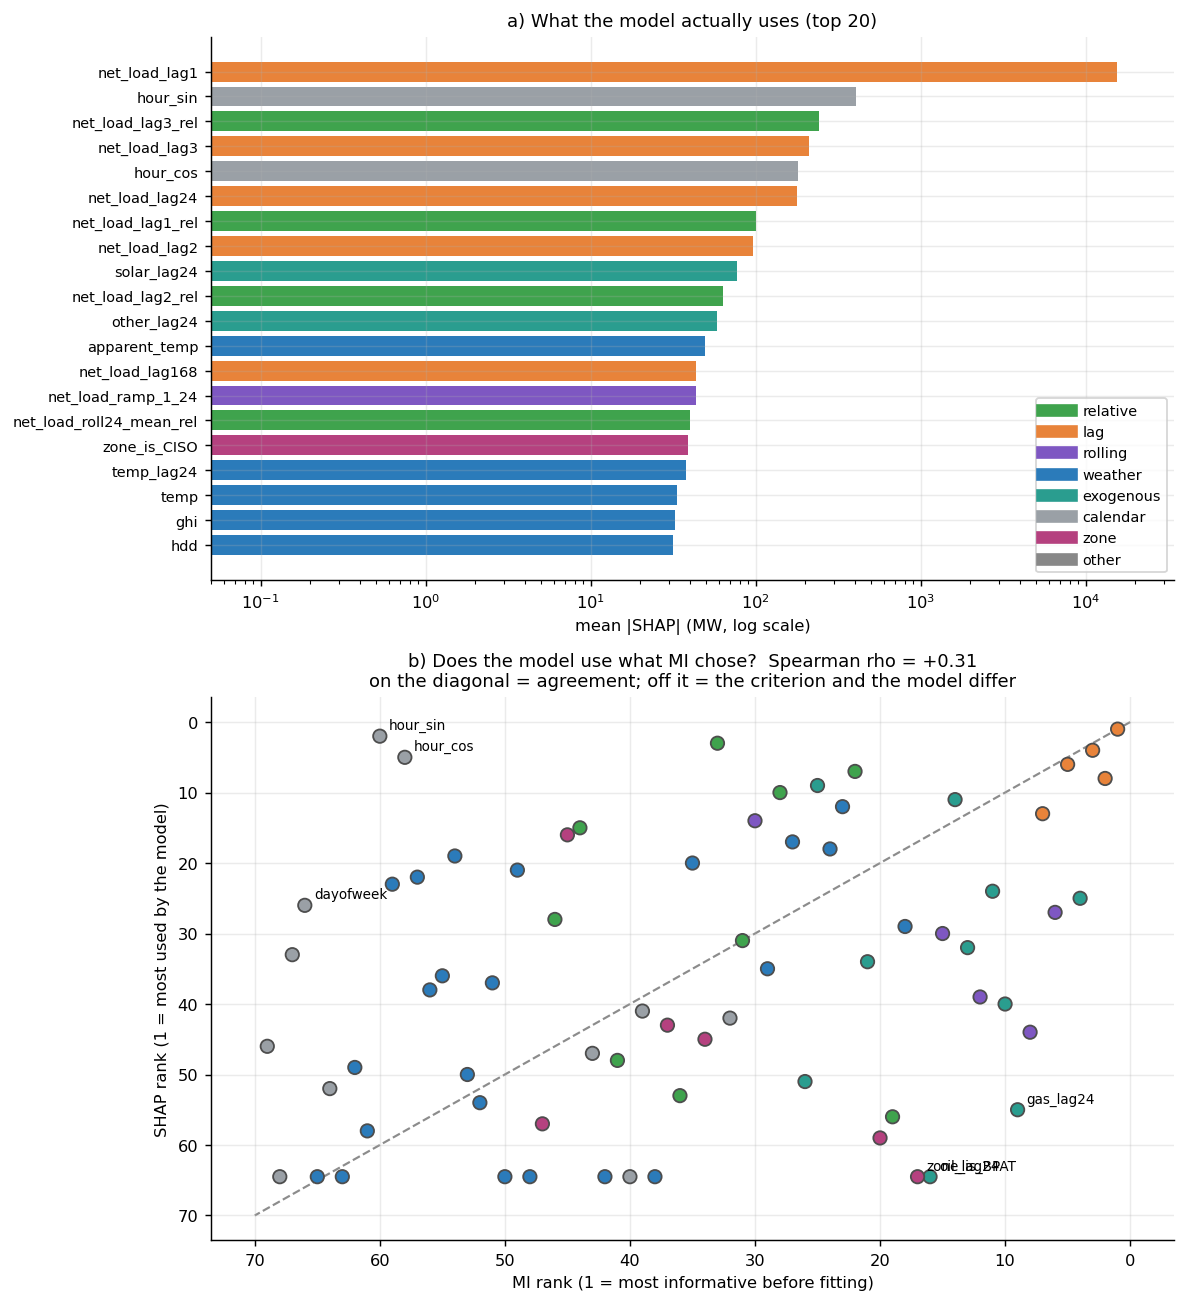

Spearman(MI rank, SHAP rank) = +0.307   on 69 features

top 10 by mean |SHAP|:
  net_load_lag1                   15594.54 MW   MI rank 1 -> SHAP rank 1
  hour_sin                          406.52 MW   MI rank 60 -> SHAP rank 2
  net_load_lag3_rel                 241.06 MW   MI rank 33 -> SHAP rank 3
  net_load_lag3                     210.13 MW   MI rank 3 -> SHAP rank 4
  hour_cos                          179.77 MW   MI rank 58 -> SHAP rank 5
  net_load_lag24                    177.50 MW   MI rank 5 -> SHAP rank 6
  net_load_lag1_rel                 100.71 MW   MI rank 22 -> SHAP rank 7
  net_load_lag2                      96.83 MW   MI rank 2 -> SHAP rank 8
  solar_lag24                        77.10 MW   MI rank 25 -> SHAP rank 9
  net_load_lag2_rel                  63.01 MW   MI rank 28 -> SHAP rank 10

biggest disagreements (MI rank vs SHAP rank):
  hour_sin                       MI  60 -> SHAP   2  (-58)
  hour_cos                       MI  58 -> SHAP   5  (-53)
  oil_lag24        

In [22]:
# WHAT: mean |SHAP| per feature against the MI rank that selected it.
# WHY:  MI ranks BEFORE a model exists; SHAP measures what the model USED. Where
#       they disagree, the selection criterion and the model disagree.
# NOTE: TreeExplainer on a subsample -- exact for tree ensembles, and the ranking
#       is stable long before the individual values are precise.
#       NOT causal, NOT the holdout, NOT notebook 07's job. See the markdown.
import shap

SHAP_N = 4000
Xs_all = pd.DataFrame(pipe_full[:-1].transform(df), columns=feat_names)
Xs = Xs_all.sample(min(SHAP_N, len(Xs_all)), random_state=cfg.SEED)
sv = shap.TreeExplainer(pipe_full.named_steps["model"]).shap_values(Xs, check_additivity=False)
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(9.2, 10.1))
ax = axes[0]
sh = shap_imp.head(20)[::-1]
# LOG axis, and the reason is the finding: net_load_lag1 carries the LEVEL of the
# prediction, so its mean |SHAP| is ~38x the next feature. On a linear axis every
# other bar collapses to invisibility and the figure stops informing.
ax.barh(range(len(sh)), sh.clip(lower=0.05).values,
        color=[FAMC[fam(c)] for c in sh.index])
ax.set_xscale("log"); ax.set_xlim(0.05, shap_imp.max() * 2.2)
ax.set_yticks(range(len(sh))); ax.set_yticklabels(sh.index, fontsize=8)
ax.set_xlabel("mean |SHAP| (MW, log scale)")
ax.set_title("a) What the model actually uses (top 20)", fontsize=10)
handles = [plt.Line2D([], [], color=v, lw=7, label=k) for k, v in FAMC.items()]
ax.legend(handles=handles, fontsize=8, loc="lower right")

ax = axes[1]
mi_r = mi_mean.rank(ascending=False)
sh_r = shap_imp.rank(ascending=False)
common = [c for c in feat_names if c in mi_r.index]
ax.scatter([mi_r[c] for c in common], [sh_r[c] for c in common],
           c=[FAMC[fam(c)] for c in common], s=55, edgecolor="0.3", zorder=3)
lim = len(common) + 1
ax.plot([0, lim], [0, lim], "--", color="0.55", lw=1.2, zorder=1)
disagree = sorted(common, key=lambda c: -abs(mi_r[c] - sh_r[c]))[:6]
for c in disagree:
    ax.annotate(c, (mi_r[c], sh_r[c]), fontsize=7.5, xytext=(5, 4),
                textcoords="offset points")
rho = float(pd.Series([mi_r[c] for c in common]).corr(
    pd.Series([sh_r[c] for c in common]), method="spearman"))
ax.set_xlabel("MI rank (1 = most informative before fitting)")
ax.set_ylabel("SHAP rank (1 = most used by the model)")
ax.set_title(f"b) Does the model use what MI chose?  Spearman rho = {rho:+.2f}\n"
             "on the diagonal = agreement; off it = the criterion and the model differ",
             fontsize=10)
ax.grid(alpha=0.25); ax.invert_xaxis(); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(cfg.FIGURES / "02_shap_selection.png", bbox_inches="tight")
plt.show()

print(f"Spearman(MI rank, SHAP rank) = {rho:+.3f}   on {len(common)} features")
print("\ntop 10 by mean |SHAP|:")
for c in shap_imp.index[:10]:
    print(f"  {c:30s} {shap_imp[c]:9.2f} MW   MI rank {mi_r[c]:.0f} -> SHAP rank {sh_r[c]:.0f}")
print("\nbiggest disagreements (MI rank vs SHAP rank):")
for c in disagree:
    print(f"  {c:30s} MI {mi_r[c]:3.0f} -> SHAP {sh_r[c]:3.0f}  ({sh_r[c]-mi_r[c]:+.0f})")
print(f"\nshare of total |SHAP| held by the top 10: "
      f"{shap_imp.head(10).sum()/shap_imp.sum()*100:.1f}%")

**What I see:** The two rankings disagree: Spearman ρ = **+0.31** over 69 features. `net_load_lag1` dominates at **15,595 MW** mean |SHAP|, about 38× the next feature; the top ten hold **95.6%** of the total. MI under-ranks the calendar: `hour_sin` is MI rank 60 but SHAP rank **2**, `hour_cos` 58 → 5, `dayofweek` 66 → 26. MI over-ranks redundant history: `gas_lag24` 9 → 55, `oil_lag24` 16 → 64, `zone_is_BPAT` 17 → 64.

**What it means:** Same finding as §2.20. A fuel lag tracks the load level, so its MI is high, but it adds little once the model has last hour's net load. The hour sine has little marginal information but tells the model where on the daily curve it is. `lag1` sets the level of the prediction and the other features adjust around it.

**What I do:** Keep every feature; do not trim on MI or on SHAP alone. The full SHAP analysis is in notebook 07.


### 2.22 — The recommended feature set

Collect the decisions of 2.7 and 2.17–2.21 (one-hot encoding, relative family on, `k='all'`, 69 features) and write them to `results.json` so notebook 04 reads them.


In [23]:
# WHAT: collect notebook 02's decisions and hand them to notebook 04.
# WHY:  a notebook that ends in four diagnostics and no decision has not finished.
# The dict is inline at the save site, not built as a name first: src/provenance.py
# reads these keys statically, and a payload passed by name is unreadable to it --
# which is why nb02 was the one notebook reported UNVERIFIABLE. R.save returns the
# merged block, so `nb02_out` below is that block (this cell's keys, plus the ones
# the §2.7 save cell wrote, plus `_written_at`) rather than just this cell's payload.
nb02_out = R.save("nb02", dict(
    encoding_mae_mean={e: float(s.mean()) for e, s in enc_scores.items()},
    encoding_mae_sd={e: float(s.std()) for e, s in enc_scores.items()},
    encoding_mae_folds={e: [float(v) for v in s] for e, s in enc_scores.items()},
    encoding_chosen="onehot",
    zone_identity_worth_mw=float(enc_scores["none"].mean() - enc_scores["onehot"].mean()),
    target_vs_onehot_mw=float(enc_scores["target"].mean() - enc_scores["onehot"].mean()),
    per_zone_relative_mae={k: float(v.mean()) for k, v in rel_scores.items()},
    per_zone_relative_delta_folds=[float(v) for v in rel_delta],
    per_zone_relative_features=rel_names,
    mi_mean={c: float(v) for c, v in mi_mean.items()},
    mi_rank_spread={c: float(v) for c, v in (mi_rank.max(axis=1) - mi_rank.min(axis=1)).items()},
    # JSON has no Infinity. The exactly-dependent features live in their own
    # list; the vif dict holds only finite values, so a reader who finds a
    # feature in `vif_infinite` knows its VIF is not merely large.
    vif={c: float(v) for c, v in vif.items() if np.isfinite(v)},
    vif_infinite=sorted(c for c, v in vif.items() if not np.isfinite(v)),
    vif_over_10=int((vif > 10).sum()),
    forward_curve={int(k): float(v) for k, v in fwd.items()},
    forward_knee_k=int(knee),
    forward_knee_mae=float(fs[knee]),
    shap_mean_abs={c: float(v) for c, v in shap_imp.items()},
    shap_mi_rank_spearman=float(rho),
    n_features=int(len(feat_names)),
))
print("notebook 02 decisions written to results.json")
print(f"  encoding        : {nb02_out['encoding_chosen']}")
print(f"  features         : {nb02_out['n_features']} "
      f"(knee at {nb02_out['forward_knee_k']})")
print(f"  relative family : {rel_delta.mean():+.2f} MW")
print(f"  MI/SHAP agreement: rho = {rho:+.2f}")

[results read-only] nb02: 20 key(s) verified against the ledger, nothing written
notebook 02 decisions written to results.json
  encoding        : onehot
  features         : 69 (knee at 69)
  relative family : -9.19 MW
  MI/SHAP agreement: rho = +0.31
